# Tugas Terstruktur dan Milestone Proyek UAS — Pertemuan 12
## Hyperparameter Tuning yang Terkendali pada Klasifikasi Status *Dropout* Mahasiswa Menggunakan Informasi hingga Akhir Semester Pertama (Dataset UCI #697)

---

## BAGIAN A — PENDAHULUAN

### A.1 Identitas Mahasiswa dan Informasi Tugas
| Komponen | Keterangan |
| :--- | :--- |
| **Nama Mahasiswa** | Fadli Hifziansyah |
| **NIM** | `241730042` |
| **Kelas** | `5 INF B` |
| **Mata Kuliah** | Pembelajaran Mesin (*Machine Learning*) — Pertemuan 12 |
| **Dosen Pengampu** | Bapak Ahmad Tabrani |
| **Judul Tugas** | Hyperparameter Tuning yang Terkendali |
| **Sumber Dataset Empiris** | *Predict Students' Dropout and Academic Success* — UCI Machine Learning Repository ID #697 (DOI Resmi Dataset: `10.24432/C5MC89`; Artikel Deskripsi: Realinho et al., 2022, DOI: `10.3390/data7110146`; Lisensi `CC BY 4.0`; berkas lokal `dataset-asli.csv`) |
| **Berkas Notebook Final (Hasil Audit)** | `241730042_Fadli_Hifziansyah_P12_TugasML_FINAL.ipynb` *(berkas sebelumnya dipertahankan utuh)* |

---

### A.2 Tujuan Pembelajaran dan Peta Kepatuhan terhadap Instruksi Dosen & Modul Resmi
Notebook ini disusun sebagai asesmen mandiri Pertemuan 12 sekaligus kelanjutan langsung proyek UAS dari Pertemuan 11. Produk akhir yang dibuktikan secara terprogram meliputi: (1) model *baseline* dan model sebelum tuning, (2) ruang pencarian (*search space*) kecil yang beralasan ilmiah, (3) strategi *5-Fold Stratified Cross-Validation* di dalam `Pipeline` bebas *data leakage*, (4) hasil evaluasi seluruh kandidat beserta 5 konfigurasi terbaik, (5) `best_params_`, `best_score_`, dan `best_estimator_`, (6) pencatatan aktual waktu dan biaya komputasi, serta (7) evaluasi akhir satu tahap pada *Test Set* yang terlindungi selama tuning.

| Instruksi Langkah Kerja Dosen & Modul P12 | Lokasi pada Notebook |
| :--- | :--- |
| **Langkah 1:** Model, parameter, dan *hyperparameter* yang dioptimalkan | **Bagian B.1–B.2** & **Bagian E.1** |
| **Langkah 2:** Penentuan metrik utama (`Average Precision` / `AP`) untuk memilih konfigurasi | **Bagian B.4** & **Bagian E.2–E.4** |
| **Langkah 3:** Tabel ruang pencarian beserta alasan ilmiah setiap nilai kandidat | **Bagian E.1** |
| **Langkah 4:** Perhitungan jumlah proses `fit` (`60` CV fit + `1` *refit* = `61` fit) | **Bagian E.2** |
| **Langkah 5:** Eksekusi `GridSearchCV` menggunakan `5-Fold Stratified Cross-Validation` di dalam `Pipeline` | **Bagian E.2–E.4** |
| **Langkah 6:** Pencatatan aktual waktu dan biaya komputasi proses tuning (`time.perf_counter()`) | **Bagian E.2–E.4** |
| **Langkah 7:** Lima konfigurasi terbaik beserta *mean* dan *standard deviation* skor validasi silang | **Bagian E.5** |
| **Langkah 8:** Analisis kritis apakah perbedaan skor antarkonfigurasi cukup berarti + analisis *overfitting* | **Bagian E.6** |
| **Langkah 9:** Pemilihan `best_estimator_` berdasarkan hasil *cross-validation* | **Bagian E.7** |
| **Langkah 10:** Evaluasi `best_estimator_` hanya pada tahap akhir di *Test Set* setelah seluruh keputusan dikunci | **Bagian F** (Validasi, Kalibrasi, Threshold) & **Bagian G.1–G.3** (*Test Set*) |
| **Langkah 11:** Perbandingan adil *baseline*, model sebelum tuning, dan `best_estimator_` | **Bagian F.1–F.4** (*Validation*) & **Bagian G.1–G.3** (*Test Set*) |
| **Langkah 12:** Paragraf justifikasi konfigurasi untuk artikel ilmiah UAS | **Bagian G.4** |
| **Modul Seksi 11, 13–17 & Latihan Analitis 1–5:** Log tuning, analisis kesalahan $\ge 3$ kasus, 5 soal analitis, kesimpulan 250–400 kata, integritas & AI, *checklist* | **Bagian H.1–H.9** |

---

### A.3 Konteks Penelitian Pertemuan 11 yang Dipertahankan
Penelitian ini melanjutkan studi pada dataset publik **Predict Students' Dropout and Academic Success (UCI ID #697)** yang menghimpun `4.424` mahasiswa program sarjana dari 17 program studi di *Instituto Politécnico de Portalegre*, Portugal, dengan `36` fitur prediktor dan `1` kolom `Target` tiga kelas (`Graduate = 2.209 [49,93%]`, `Dropout = 1.421 [32,12%]`, `Enrolled = 794 [17,95%]`). Seluruh ketetapan metodologis P11 dipertahankan secara ketat:
1. **Definisi Target Biner:** Kelas positif (`1`) adalah `Dropout` (`32,12%`), sedangkan kelas negatif (`0`) adalah gabungan `Enrolled + Graduate` (`67,88%`), yang bermakna **status mahasiswa tidak dilabeli `Dropout` pada *endpoint* pengamatan dataset**. Mahasiswa berstatus `Enrolled` masih aktif terdaftar saat periode pengamatan ditutup (*right-censored*) dan **tidak** boleh diartikan pasti akan lulus.
2. **Titik Waktu Prediksi & Spesifikasi 28 Fitur Konservatif:** Prediksi dilakukan **tepat setelah evaluasi akademik Semester Pertama berakhir**. Enam fitur Semester Kedua dikeluarkan mutlak karena merepresentasikan masa depan, sedangkan `Debtor` dan `Tuition fees up to date` (yang tidak memiliki *timestamp* per semester pada dokumentasi publik) tidak dimasukkan ke spesifikasi utama sehingga model tetap memakai **28 fitur konservatif** P11.

---

### A.4 Hubungan Eksperimen Pertemuan 11 dan Pertemuan 12
1. **Mengapa *Logistic Regression* pada P11 perlu di-*tuning*:** Pada P11, *Logistic Regression* dijalankan menggunakan pengaturan bawaan (`C = 1,0`, `class_weight = None`) dan fokus kajian diarahkan pada evaluasi kurva ROC/PR, kalibrasi probabilitas, matriks biaya `1:4`, serta penentuan *threshold* operasional. Padahal, setelah prapemrosesan `ColumnTransformer` (termasuk *One-Hot Encoding* terhadap 9 variabel kategorikal nominal) di-*fit* pada *Training Set* (`n = 2.654`), `28` fitur mentah konservatif melebar menjadi **`213` kolom hasil transformasi** (`~2.123` baris per lipatan latih CV), sehingga kekuatan regularisasi $L_2$ (`C`) dan skema bobot kelas (`class_weight`) sangat relevan untuk diuji secara sistematis.
2. **Hyperparameter yang berpotensi memengaruhi performa:** Kekuatan kebalikan regularisasi `C` mengendalikan keseimbangan *bias–variance* pada bobot `213` kolom fitur hasil transformasi tersebut, sedangkan `class_weight` mengubah penalti fungsi kerugian logaritmik antara kelas positif minoritas (`32,14%` di data latih) dan kelas negatif mayoritas (`67,86%`).
3. **Mengapa `Pipeline` dan pembagian data P11 wajib dipertahankan:** Menggunakan `ColumnTransformer` dan pembagian berstrata `60% / 20% / 20%` (`SEED = 42`) yang persis sama menjamin tidak ada variabel perancu (*confounding*) akibat perubahan prapemrosesan atau perubahan sampel, sehingga setiap perbedaan skor murni berasal dari perubahan *hyperparameter*.
4. **Mengapa hasil *tuning* wajib dibandingkan dengan model sebelum *tuning*:** Optimasi *hyperparameter* memerlukan biaya komputasi tambahan; pembandingan langsung terhadap konfigurasi P11 (`C = 1,0`, `class_weight = None`) dan *baseline* `DummyClassifier` diperlukan untuk menguji secara jujur apakah *tuning* benar-benar memberi peningkatan substantif atau hanya selisih marginal.
5. **Peran hasil P12 bagi artikel ilmiah UAS:** Eksperimen P12 menyediakan dasar empiris yang terdokumentasi untuk menetapkan konfigurasi regularisasi, pembobotan kelas, perlunya kalibrasi pascapelatihan, dan *threshold* operasional yang paling dapat dipertanggungjawabkan pada naskah artikel UAS.

---

### A.5 Rumusan Analisis: Keputusan yang Dibantu, Unit Analisis, dan Risiko Kesalahan
1. **Masalah dan keputusan yang dibantu:** Membantu pengelola akademik atau dosen pembimbing akademik dalam memprioritaskan peninjauan dini dan pendampingan belajar bagi mahasiswa yang menunjukkan profil risiko `Dropout` tinggi pada akhir Semester Pertama *(catatan: model memprediksi asosiasi risiko pada data observasional, bukan membuktikan penyebab kausal putus studi maupun menjamin keberhasilan intervensi)*.
2. **Unit analisis dan waktu keluaran:** Satu observasi mewakili **satu mahasiswa sarjana**, dengan skor probabilitas yang dihitung satu kali setelah nilai Semester Pertama resmi direkapitulasi sebelum Semester Kedua dimulai.
3. **Data yang tersedia saat keputusan:** Sebanyak `28` atribut konservatif yang mencakup profil demografi pendaftaran, kualifikasi masuk, indikator sosial-ekonomi ber-*timestamp* jelas, indikator makroekonomi saat masuk, dan 6 indikator kurikuler Semester Pertama.
4. **Baseline dan metrik pemilihan konfigurasi:** *Baseline* tanpa pembelajaran pola adalah `DummyClassifier(strategy="prior")`, referensi pra-*tuning* adalah `LogisticRegression(C=1.0, class_weight=None)`, dan metrik utama pemilihan *hyperparameter* pada `GridSearchCV` adalah **Average Precision (`AP`)**.
5. **Risiko kesalahan prediksi:** *False Negative* ($\text{FN}$) menyebabkan mahasiswa berisiko tinggi terlewat dari pemantauan awal (diberi bobot relatif lebih berat pada matriks biaya simulasi `1:4`), sedangkan *False Positive* ($\text{FP}$) menyerap kuota pendampingan yang terbatas dan berisiko menimbulkan label negatif yang tidak perlu apabila disalahgunakan sebagai vonis administratif.


In [16]:
# Bagian A.1 (Kode): Pengisian Struktur Identitas Sesuai Modul Resmi Pertemuan 12
identitas = {
    "nama": "Fadli Hifziansyah",
    "nim": "241730042",
    "kelas": "5 INF B",
    "mata_kuliah": "Machine Learning — Pertemuan 12",
    "dosen_pengampu": "Bapak Ahmad Tabrani",
    "judul_tugas": "Hyperparameter Tuning yang Terkendali pada Klasifikasi Risiko Dropout Mahasiswa (UCI #697)",
    "sumber_data": (
        "Predict Students' Dropout and Academic Success — UCI Machine Learning Repository ID #697 "
        "(DOI Dataset: 10.24432/C5MC89; Artikel: 10.3390/data7110146; Lisensi CC BY 4.0; dataset-asli.csv)"
    ),
    "tanggal_pengerjaan": "2026-11-28",
}
for kunci, nilai in identitas.items():
    print(f"{kunci:20s}: {nilai}")


nama                : Fadli Hifziansyah
nim                 : 241730042
kelas               : 5 INF B
mata_kuliah         : Machine Learning — Pertemuan 12
dosen_pengampu      : Bapak Ahmad Tabrani
judul_tugas         : Hyperparameter Tuning yang Terkendali pada Klasifikasi Risiko Dropout Mahasiswa (UCI #697)
sumber_data         : Predict Students' Dropout and Academic Success — UCI Machine Learning Repository ID #697 (DOI Dataset: 10.24432/C5MC89; Artikel: 10.3390/data7110146; Lisensi CC BY 4.0; dataset-asli.csv)
tanggal_pengerjaan  : 2026-11-28


---
## BAGIAN B — LANDASAN TEORI DAN PRINSIP METODOLOGI TUNING

### B.1 Perbedaan Parameter Model dan *Hyperparameter* (Langkah 1)
Dalam pembelajaran mesin, pembedaan antara **parameter model** dan **hyperparameter** sangat mendasar:
* **Parameter Model (*Model Parameters*):** Besaran internal yang **dipelajari secara otomatis dari data latih** melalui optimasi fungsi kerugian saat pemanggilan `.fit()`. Pada *Logistic Regression*, parameter model meliputi vektor bobot koefisien fitur $\mathbf{w}$ (`coef_`, berukuran `1 × 213` kolom hasil transformasi dari `28` fitur mentah pada *Training Set*) dan konstanta bias $b$ (`intercept_`).
* **Hyperparameter:** Pengaturan eksternal yang **ditetapkan oleh peneliti sebelum satu proses `.fit()` dimulai** untuk mengendalikan kapasitas model, penalti regularisasi, pembobotan kelas, maupun perilaku konvergensi algoritma optimasi. Nilai *hyperparameter* tidak diperbarui oleh gradien fungsi kerugian di dalam satu pelatihan, melainkan dipilih melalui prosedur evaluasi validasi silang di luar pelatihan tunggal.

| Komponen pada `LogisticRegression` | Jenis | Fungsi Teknis | Dioptimalkan pada `GridSearchCV`? |
| :--- | :--- | :--- | :--- |
| `coef_` ($\mathbf{w}$) | **Parameter model** | Bobot kontribusi setiap fitur tertransformasi terhadap *log-odds* kelas positif | Tidak langsung (dipelajari otomatis saat `.fit()`) |
| `intercept_` ($b$) | **Parameter model** | Konstanta dasar (*log-odds* saat seluruh fitur bernilai nol) | Tidak langsung (dipelajari otomatis saat `.fit()`) |
| `C` | **Hyperparameter utama** | Kebalikan kekuatan regularisasi $L_2$ ($\lambda = 1/C$); mengendalikan penyusutan bobot | **Ya** (`[0.03, 0.1, 0.3, 1.0, 3.0, 10.0]`) |
| `class_weight` | **Hyperparameter utama** | Pengali bobot kerugian per kelas pada fungsi *binary cross-entropy* | **Ya** (`[None, "balanced"]`) |
| `l1_ratio` (`= 0.0`, regularisasi $L_2$) | **Hyperparameter struktural** | Menetapkan penalti kuadratik murni $L_2$ ($\|\mathbf{w}\|_2^2$) secara eksplisit. Sesuai dokumentasi resmi `Scikit-learn 1.9.1`, parameter `penalty` telah berstatus *deprecated* sejak versi `1.8` dan dijadwalkan dihapus pada versi `1.10`, sehingga `l1_ratio=0.0` ditetapkan langsung pada konstruktor agar tidak mengandalkan *default* tersembunyi | Tidak, ditetapkan tetap (`l1_ratio=0.0`) sesuai P11 |
| `solver` | **Hyperparameter algoritma** | Algoritma optimasi kuasi-Newton `lbfgs` untuk fungsi mulus berpenalti $L_2$ | Tidak, ditetapkan tetap (`"lbfgs"`) |
| `max_iter` | **Hyperparameter konfigurasi** | Batas maksimum iterasi konvergensi `lbfgs` | Tidak, ditetapkan tetap (`2000`) agar bebas gagal konvergen |
| `random_state` | **Konfigurasi reproduksibilitas** | Benih deterministik internal | Tidak, ditetapkan tetap (`SEED = 42`) |

---

### B.2 Formulasi *Logistic Regression*, Regularisasi $L_2$ (`C`), dan `class_weight`
Pada klasifikasi biner dengan label $y_i \in \{0, 1\}$, *Logistic Regression* memodelkan probabilitas bersyarat $p_i = P(y_i = 1 \mid \mathbf{x}_i) = \frac{1}{1 + \exp(-(\mathbf{w}^\top \mathbf{x}_i + b))}$. Dalam formulasi `Scikit-learn`, estimasi parameter $(\hat{\mathbf{w}}, \hat{b})$ meminimalkan fungsi objektif berpenalti $L_2$:

$$\min_{\mathbf{w},\, b} \; \frac{1}{2} \mathbf{w}^\top \mathbf{w} \;+\; C \sum_{i=1}^{n} \omega_{y_i} \Big[ -y_i \log(p_i) - (1 - y_i)\log(1 - p_i) \Big]$$

* **Peran `C`:** Nilai `C` kecil memperkecil suku kerugian data relatif terhadap penalti $\frac{1}{2}\|\mathbf{w}\|_2^2$ (regularisasi kuat $\rightarrow$ koefisien menyusut mendekati nol, varians turun, namun berisiko *underfitting* bila terlalu kecil). Sebaliknya, nilai `C` besar melemahkan regularisasi sehingga model leluasa memperbesar koefisien kategori langka hasil *One-Hot Encoding*, yang meningkatkan kecocokan di data latih tetapi berisiko *overfitting* pada lipatan validasi.
* **Peran `class_weight`:** Pada `None`, seluruh observasi memiliki bobot $\omega_0 = \omega_1 = 1$. Pada `"balanced"`, bobot disesuaikan berbanding terbalik terhadap frekuensi kelas latih ($\omega_c = \frac{n}{2 n_c}$), sehingga pada prevalensi positif `32,14%` kesalahan kelas positif diberi bobot sekitar `1,56` kali dan kelas negatif `0,74` kali. Penyesuaian ini menggeser skala probabilitas ke atas (sebagaimana terbukti meningkatkan `ECE` pada P11) dan tidak otomatis memperbaiki urutan peringkat probabilitas (`AP`).

---

### B.3 `GridSearchCV` vs. `RandomizedSearchCV` dan *5-Fold Stratified Cross-Validation*
* **`GridSearchCV` (Strategi yang Dipilih):** Mengevaluasi **seluruh hasil kali Kartesius** dari nilai kandidat yang ditentukan. Karena ruang pencarian kita berdimensi rendah dan terfokus (`6` nilai `C` $\times$ `2` pilihan `class_weight` $= 12$ kombinasi), evaluasi menyeluruh sangat terjangkau secara komputasi, deterministik penuh, dan memungkinkan pemetaan kurva respons regularisasi secara utuh tanpa celah pengambilan sampel.
* **`RandomizedSearchCV` (Pembanding Konseptual):** Mengambil sejumlah tetap `n_iter` kombinasi secara acak dari ruang diskrit atau distribusi kontinu. Metode ini jauh lebih efisien ketika jumlah *hyperparameter* banyak (berdimensi tinggi), terdapat *hyperparameter* kontinu yang sensitif sedangkan sebagian lainnya berdaya pengaruh lemah, atau anggaran waktu komputasi membatasi jumlah `fit` di bawah ukuran grid penuh.
* **`StratifiedKFold (n_splits=5)`:** Membagi *Training Set* (`n = 2.654`) menjadi 5 lipatan saling lepas berukuran `~531` observasi per lipatan sambil menjaga proporsi kelas positif `Dropout` (`~32,14%`) seragam di setiap lipatan.

---

### B.4 Pemilihan Metrik Utama (`Average Precision`), Biaya Komputasi, dan Pencegahan *Data Leakage*
1. **Mengapa `Average Precision (AP)` dijadikan metrik utama (`refit="AP"`):** Populasi positif `Dropout` (`32,12%`) lebih kecil dibandingkan gabungan non-*Dropout* (`67,88%`). Mengoptimalkan `Accuracy` bergantung pada ambang `0,50` dan kurang peka terhadap kelas positif, sedangkan `AP` ($\sum_n (R_n - R_{n-1}) P_n$) merangkum kualitas pengurutan probabilitas sepanjang seluruh kurva *Precision–Recall* tanpa bias interpolasi linier trapesium (*Trapezoidal PR-AUC*). `ROC-AUC` tetap dicatat berdampingan sebagai metrik sekunder kemampuan diskriminasi global, sementara pemilihan *threshold* berbasis biaya dilakukan terpisah pada *Validation Set* sesudah `best_estimator_` diperoleh.
2. **Biaya Komputasi:** Mencakup **waktu nyata (*wall-clock elapsed time*)** dari awal hingga akhir pencarian, **rata-rata dan simpangan baku waktu satu kali `fit` (`mean_fit_time`, `std_fit_time`)**, serta **waktu pelatihan ulang model terbaik (`refit_time_`)**. Pada eksekusi paralel (`n_jobs > 1`), *wall-clock time* lebih pendek daripada jumlahan seluruh waktu `fit` tunggal ditambah sedikit *overhead* manajemen pekerja paralel.
3. **Pencegahan *Data Leakage* dan Perlindungan *Test Set*:**
   ```text
   Training Set (n = 2.654; 60%)
     └── Stratified 5-Fold Split (4 fold latih [~2.123] | 1 fold validasi [~531])
           └── Pipeline: ColumnTransformer.fit_transform(X_fold_train) -> LogisticRegression.fit()
                 └── Pipeline.predict_proba(X_fold_val) -> Hitung AP & ROC-AUC per fold
                       └── Rata-rata 5 fold -> Pilih best_params_ -> Refit 1x di seluruh Training Set (n = 2.654)
                                                                            │
   Validation Set (n = 885; 20%) ◄── Evaluasi best_estimator_, audit kalibrasi, & kunci threshold biaya/kapasitas
                                                                            │
   Test Set (n = 885; 20%)       ◄── HANYA dievaluasi satu tahap di akhir setelah seluruh konfigurasi terkunci
   ```
   > **Catatan Transparansi Riwayat *Test Set*:** Demi menjaga keadilan pembandingan langsung antara Pertemuan 11 dan Pertemuan 12, pembagian berstrata `60/20/20` dengan `SEED = 42` dipertahankan identik. Perlu dinyatakan secara jujur bahwa partisi *Test Set* yang sama pernah dilaporkan satu kali pada evaluasi akhir Pertemuan 11; namun selama seluruh rangkaian perancangan *search space*, eksekusi `GridSearchCV`, pemeriksaan kalibrasi, dan penentuan *threshold* pada Pertemuan 12, *Test Set* **sama sekali tidak dimasukkan maupun dibaca** hingga tahap evaluasi akhir Bagian G.


---
## BAGIAN C — PERSIAPAN LINGKUNGAN, AUDIT DATA, DAN REPRODUKSI PIPELINE P11


In [17]:
# Bagian C.1 & C.2 (Kode): Import Pustaka, Penetapan SEED, dan Pencatatan Versi Lingkungan
from datetime import datetime
from pathlib import Path
import hashlib
import os
import platform
import random
import sys
import time
import urllib.request
import warnings

from IPython.display import display
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\..*")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 9.5

LUARAN_P12_DIR = Path("luaran_p12_final")
LUARAN_TAB_DIR = LUARAN_P12_DIR / "tabel"
LUARAN_VIS_DIR = LUARAN_P12_DIR / "grafik"
LUARAN_TAB_DIR.mkdir(parents=True, exist_ok=True)
LUARAN_VIS_DIR.mkdir(parents=True, exist_ok=True)

CPU_COUNT_LOGICAL = os.cpu_count() or 1
df_lingkungan = pd.DataFrame([
    {"Komponen Lingkungan": "Sistem Operasi & Arsitektur", "Spesifikasi Aktual": f"{platform.system()} {platform.release()} ({platform.machine()})"},
    {"Komponen Lingkungan": "Versi Python", "Spesifikasi Aktual": sys.version.split()[0]},
    {"Komponen Lingkungan": "Versi NumPy", "Spesifikasi Aktual": np.__version__},
    {"Komponen Lingkungan": "Versi Pandas", "Spesifikasi Aktual": pd.__version__},
    {"Komponen Lingkungan": "Versi Scikit-learn", "Spesifikasi Aktual": sklearn.__version__},
    {"Komponen Lingkungan": "Versi Matplotlib / Seaborn", "Spesifikasi Aktual": f"{matplotlib.__version__} / {sns.__version__}"},
    {"Komponen Lingkungan": "Jumlah Logical CPU Cores", "Spesifikasi Aktual": f"{CPU_COUNT_LOGICAL} core"},
    {"Komponen Lingkungan": "Random Seed Eksperimen", "Spesifikasi Aktual": f"SEED = {SEED}"},
])
print("=== TABEL SPESIFIKASI LINGKUNGAN KOMPUTASI & REPRODUKSIBILITAS ===")
display(df_lingkungan)


=== TABEL SPESIFIKASI LINGKUNGAN KOMPUTASI & REPRODUKSIBILITAS ===


,Komponen Lingkungan,Spesifikasi Aktual
0,Sistem Operasi & Arsitektur,Windows 11 (AMD64)
1,Versi Python,3.14.4
2,Versi NumPy,2.4.4
3,Versi Pandas,3.1.1
4,Versi Scikit-learn,1.9.1
5,Versi Matplotlib / Seaborn,3.10.9 / 0.13.2
6,Jumlah Logical CPU Cores,16 core
7,Random Seed Eksperimen,SEED = 42


In [18]:
# Bagian C.3 - C.5 (Kode): Pembacaan dataset-asli.csv, Audit Data, Spesifikasi 28 Fitur P11, Pipeline, & Split 60/20/20
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/fadli154/mesin-learning-smt5/refs/heads/main/dataset-asli.csv"
)
EXPECTED_LF_SHA256_FULL = "19737f02127e85ef29af536e46888a7721b6c530c3e1c6aedfbb09109c030a71"


def temukan_atau_unduh_dataset(
    nama_file: str = "dataset-asli.csv",
    fallback_url: str = GITHUB_RAW_URL,
) -> tuple[Path, str]:
    kandidat_lokal = [
        Path(nama_file),
        Path("..") / nama_file,
        Path("..") / "Pertemuan 11" / nama_file,
        Path("Pertemuan 11") / nama_file,
    ]
    for p in kandidat_lokal:
        if p.is_file():
            return p, f"Berkas lokal ({p})"
    target_unduh = Path(nama_file)
    print(f"Berkas lokal '{nama_file}' tidak ditemukan; mengunduh dari cermin GitHub Raw...")
    req = urllib.request.Request(fallback_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(target_unduh, "wb") as out_f:
        out_f.write(resp.read())
    return target_unduh, f"Unduhan otomatis cermin GitHub Raw ({target_unduh})"


path_dataset, sumber_dataset_aktif = temukan_atau_unduh_dataset("dataset-asli.csv")
raw_bytes = path_dataset.read_bytes()
sha256_raw_full = hashlib.sha256(raw_bytes).hexdigest()
sha256_lf_full = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()
assert sha256_lf_full == EXPECTED_LF_SHA256_FULL, "SHA-256 (LF) dataset berbeda dari berkas acuan P11!"

df_uci = pd.read_csv(path_dataset, sep=";", encoding="utf-8-sig")
df_uci.columns = [c.strip() for c in df_uci.columns]
df_uci["obs_id"] = [f"OBS_{i:04d}" for i in range(1, len(df_uci) + 1)]
df_uci["label_dropout"] = (df_uci["Target"] == "Dropout").astype(int)

# Spesifikasi 28 fitur konservatif akhir Semester Pertama (identik 100% dengan Pertemuan 11)
fitur_numerik = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
]
fitur_biner = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Scholarship holder",
    "International",
]
fitur_kategorikal_nominal = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
fitur_konservatif_28 = fitur_numerik + fitur_biner + fitur_kategorikal_nominal
fitur_sem2_dikeluarkan = [c for c in df_uci.columns if "2nd sem" in c]
fitur_sensitivitas_30_tambahan = ["Debtor", "Tuition fees up to date"]

assert len(fitur_konservatif_28) == 28
assert set(fitur_konservatif_28).isdisjoint(set(fitur_sem2_dikeluarkan))
assert set(fitur_konservatif_28).isdisjoint(set(fitur_sensitivitas_30_tambahan))

# Reproduksi eksak pembagian berstrata 60/20/20 P11 (label Test Set ditunda hingga Bagian G)
idx_all = np.arange(len(df_uci))
idx_dev, idx_test_locked = train_test_split(
    idx_all, test_size=0.20, stratify=df_uci["Target"], random_state=SEED
)
df_dev_pool = df_uci.iloc[idx_dev].reset_index(drop=True)
df_train, df_val = train_test_split(
    df_dev_pool, test_size=0.25, stratify=df_dev_pool["Target"], random_state=SEED
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

X_train = df_train[fitur_konservatif_28].copy()
y_train = df_train["label_dropout"].to_numpy()
X_val = df_val[fitur_konservatif_28].copy()
y_val = df_val["label_dropout"].to_numpy()


def bangun_preprocessor_p11() -> ColumnTransformer:
    '''Membangun ColumnTransformer identik P11 yang selalu di-fit di dalam masing-masing fold.'''
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), fitur_numerik),
            ("bin", Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]), fitur_biner),
            (
                "nom",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                ]),
                fitur_kategorikal_nominal,
            ),
        ],
        remainder="drop",
    )


def bangun_pipeline_logreg(c_val: float = 1.0, cw_val=None) -> Pipeline:
    '''
    Pipeline utama P11/P12 dengan step 'prep' dan 'clf'.
    Sesuai dokumentasi Scikit-learn 1.9.1 (penalty deprecated sejak 1.8 & dihapus pada 1.10),
    l1_ratio=0.0 ditetapkan eksplisit bersama solver='lbfgs' untuk regularisasi murni L2.
    '''
    return Pipeline([
        ("prep", bangun_preprocessor_p11()),
        ("clf", LogisticRegression(C=c_val, class_weight=cw_val, l1_ratio=0.0, solver="lbfgs", max_iter=2000, random_state=SEED)),
    ])


print(f"Sumber dataset aktif         : {sumber_dataset_aktif} ({len(raw_bytes):,} byte)")
print(f"Full SHA-256 (LF-normalized) : {sha256_lf_full}")
print(f"Dimensi dataset & kualitas   : {df_uci.shape[0]:,} baris x 37 kolom asli | Missing = {int(df_uci.isna().sum().sum())} | Duplikat = {int(df_uci.duplicated().sum())}")
print(f"Spesifikasi fitur utama P12  : {len(fitur_konservatif_28)} fitur konservatif ({len(fitur_numerik)} numerik + {len(fitur_biner)} biner + {len(fitur_kategorikal_nominal)} nominal)")

df_audit_split_p12 = pd.DataFrame([
    {
        "Partisi Data": "Training Set (60% — Digunakan untuk 5-Fold CV & Refit)",
        "n Observasi": len(df_train),
        "Dropout (Kelas 1)": str(int((y_train == 1).sum())),
        "Non-Dropout Endpoint (Kelas 0)": str(int((y_train == 0).sum())),
        "Prevalensi Positif": f"{y_train.mean()*100:.2f}%",
        "Subkelas Graduate / Enrolled": f"{int((df_train['Target']=='Graduate').sum())} / {int((df_train['Target']=='Enrolled').sum())}",
    },
    {
        "Partisi Data": "Validation Set (20% — Kalibrasi, Threshold Biaya, & Error Analysis)",
        "n Observasi": len(df_val),
        "Dropout (Kelas 1)": str(int((y_val == 1).sum())),
        "Non-Dropout Endpoint (Kelas 0)": str(int((y_val == 0).sum())),
        "Prevalensi Positif": f"{y_val.mean()*100:.2f}%",
        "Subkelas Graduate / Enrolled": f"{int((df_val['Target']=='Graduate').sum())} / {int((df_val['Target']=='Enrolled').sum())}",
    },
    {
        "Partisi Data": "Test Set (20% — Indeks Terkunci; Tidak Disentuh Selama Tuning)",
        "n Observasi": len(idx_test_locked),
        "Dropout (Kelas 1)": "[Ditunda s.d. Evaluasi Akhir Bagian G]",
        "Non-Dropout Endpoint (Kelas 0)": "[Ditunda s.d. Evaluasi Akhir Bagian G]",
        "Prevalensi Positif": "[Ditunda s.d. Evaluasi Akhir Bagian G]",
        "Subkelas Graduate / Enrolled": "[Ditunda]",
    },
])
df_audit_split_p12.to_csv(LUARAN_TAB_DIR / "01_audit_pembagian_data_p12.csv", index=False)
print("\n=== TABEL AUDIT PEMBAGIAN DATA (SUMBER: DATASET UCI #697, SEED = 42) ===")
display(df_audit_split_p12)


Sumber dataset aktif         : Berkas lokal (dataset-asli.csv) (533,230 byte)
Full SHA-256 (LF-normalized) : 19737f02127e85ef29af536e46888a7721b6c530c3e1c6aedfbb09109c030a71
Dimensi dataset & kualitas   : 4,424 baris x 37 kolom asli | Missing = 0 | Duplikat = 0
Spesifikasi fitur utama P12  : 28 fitur konservatif (13 numerik + 6 biner + 9 nominal)

=== TABEL AUDIT PEMBAGIAN DATA (SUMBER: DATASET UCI #697, SEED = 42) ===


,Partisi Data,n Observasi,Dropout (Kelas 1),Non-Dropout Endpoint (Kelas 0),Prevalensi Positif,Subkelas Graduate / Enrolled
0,Training Set (60% — Digunakan untuk 5-Fold CV & Refit),2654,853,1801,32.14%,1325 / 476
1,"Validation Set (20% — Kalibrasi, Threshold Biaya, & Error Analysis)",885,284,601,32.09%,442 / 159
2,Test Set (20% — Indeks Terkunci; Tidak Disentuh Selama Tuning),885,[Ditunda s.d. Evaluasi Akhir Bagian G],[Ditunda s.d. Evaluasi Akhir Bagian G],[Ditunda s.d. Evaluasi Akhir Bagian G],[Ditunda]


---
## BAGIAN D — PENETAPAN DAN AUDIT *BASELINE* SEBELUM TUNING

Sebelum menjalankan pencarian *hyperparameter*, ditetapkan dua titik acuan pada skema `5-Fold Stratified Cross-Validation` yang sama di dalam *Training Set* (`n = 2.654`):
1. **Baseline Tanpa Pembelajaran Pola (`DummyClassifier(strategy="prior")`):** Selalu memprediksi probabilitas konstan sebesar prevalensi kelas positif pada lipatan latih (`~0,3214`). Model ini menetapkan batas bawah (*no-skill floor*) untuk membuktikan apakah *classifier* sungguh-sungguh mempelajari hubungan fitur dan target.
2. **Model *Logistic Regression* Sebelum Tuning (Konfigurasi P11: `C = 1,0`, `class_weight = None`):** Menggunakan regularisasi $L_2$ bawaan (`solver="lbfgs"`, `max_iter=2000`) di dalam `Pipeline` yang identik dengan Pertemuan 11. Model ini menjadi tolok ukur langsung untuk menilai apakah *tuning* pada Bagian E memberikan nilai tambah.


In [19]:
# Bagian D.1 & D.2 (Kode): Evaluasi 5-Fold CV dan Validation Awal untuk Baseline & Model Sebelum Tuning
cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_utama = {"AP": "average_precision", "ROC_AUC": "roc_auc"}

pipeline_dummy_prior = Pipeline([
    ("prep", bangun_preprocessor_p11()),
    ("clf", DummyClassifier(strategy="prior", random_state=SEED)),
])
pipeline_sebelum_tuning = bangun_pipeline_logreg(c_val=1.0, cw_val=None)

t0_dummy = time.perf_counter()
cv_res_dummy = cross_validate(pipeline_dummy_prior, X_train, y_train, cv=cv_5fold, scoring=scoring_utama, return_train_score=True)
pipeline_dummy_prior.fit(X_train, y_train)
durasi_dummy = time.perf_counter() - t0_dummy

t0_pre = time.perf_counter()
cv_res_sebelum = cross_validate(pipeline_sebelum_tuning, X_train, y_train, cv=cv_5fold, scoring=scoring_utama, return_train_score=True)
pipeline_sebelum_tuning.fit(X_train, y_train)
durasi_sebelum = time.perf_counter() - t0_pre

proba_val_dummy = pipeline_dummy_prior.predict_proba(X_val)[:, 1]
proba_val_sebelum_native = pipeline_sebelum_tuning.predict_proba(X_val)[:, 1]

n_fitur_trans = pipeline_sebelum_tuning.named_steps["prep"].transform(X_train[:5]).shape[1]
print(f"Jumlah fitur masukan ke Pipeline : {X_train.shape[1]} fitur mentah -> {n_fitur_trans} kolom hasil transformasi ColumnTransformer (di-fit pada X_train).")

# Seluruh simpangan baku (SD) dihitung eksplisit memakai np.std(..., ddof=0) [SD populasi atas 5 lipatan]
# agar konsisten 100% dengan konvensi internal GridSearchCV.cv_results_["std_test_*"].
df_baseline_audit = pd.DataFrame([
    {
        "Model Acuan Pra-Tuning": "1. Baseline Sederhana: DummyClassifier (strategy='prior')",
        "Konfigurasi Utama": "strategy='prior' (tanpa belajar pola fitur)",
        "Jumlah Fit (CV + Fit Penuh)": "5 + 1 = 6",
        "Mean CV AP ± SD [ddof=0]": f"{np.mean(cv_res_dummy['test_AP']):.4f} ± {np.std(cv_res_dummy['test_AP'], ddof=0):.4f}",
        "Mean CV ROC-AUC ± SD [ddof=0]": f"{np.mean(cv_res_dummy['test_ROC_AUC']):.4f} ± {np.std(cv_res_dummy['test_ROC_AUC'], ddof=0):.4f}",
        "Val AP (Val Set, n=885)": round(average_precision_score(y_val, proba_val_dummy), 4),
        "Val ROC-AUC (Val Set, n=885)": round(roc_auc_score(y_val, proba_val_dummy), 4),
        "Val Brier Score": round(brier_score_loss(y_val, proba_val_dummy), 4),
        "Waktu Eksekusi (detik)": round(durasi_dummy, 4),
    },
    {
        "Model Acuan Pra-Tuning": "2. Logistic Regression Sebelum Tuning (Konfigurasi P11)",
        "Konfigurasi Utama": "L2 (l1_ratio=0.0), C=1.0, class_weight=None, solver='lbfgs', max_iter=2000",
        "Jumlah Fit (CV + Fit Penuh)": "5 + 1 = 6",
        "Mean CV AP ± SD [ddof=0]": f"{np.mean(cv_res_sebelum['test_AP']):.4f} ± {np.std(cv_res_sebelum['test_AP'], ddof=0):.4f}",
        "Mean CV ROC-AUC ± SD [ddof=0]": f"{np.mean(cv_res_sebelum['test_ROC_AUC']):.4f} ± {np.std(cv_res_sebelum['test_ROC_AUC'], ddof=0):.4f}",
        "Val AP (Val Set, n=885)": round(average_precision_score(y_val, proba_val_sebelum_native), 4),
        "Val ROC-AUC (Val Set, n=885)": round(roc_auc_score(y_val, proba_val_sebelum_native), 4),
        "Val Brier Score": round(brier_score_loss(y_val, proba_val_sebelum_native), 4),
        "Waktu Eksekusi (detik)": round(durasi_sebelum, 4),
    },
])
df_baseline_audit.to_csv(LUARAN_TAB_DIR / "02_audit_baseline_dan_sebelum_tuning.csv", index=False)
print("\n=== TABEL AUDIT BASELINE & MODEL SEBELUM TUNING (SUMBER: TRAINING SET CV & VALIDATION SET) ===")
display(df_baseline_audit)


Jumlah fitur masukan ke Pipeline : 28 fitur mentah -> 213 kolom hasil transformasi ColumnTransformer (di-fit pada X_train).

=== TABEL AUDIT BASELINE & MODEL SEBELUM TUNING (SUMBER: TRAINING SET CV & VALIDATION SET) ===


,Model Acuan Pra-Tuning,Konfigurasi Utama,Jumlah Fit (CV + Fit Penuh),Mean CV AP ± SD [ddof=0],Mean CV ROC-AUC ± SD [ddof=0],"Val AP (Val Set, n=885)","Val ROC-AUC (Val Set, n=885)",Val Brier Score,Waktu Eksekusi (detik)
0,1. Baseline Sederhana: DummyClassifier (strategy='prior'),strategy='prior' (tanpa belajar pola fitur),5 + 1 = 6,0.3214 ± 0.0008,0.5000 ± 0.0000,0.3209,0.5000,0.2179,0.3472
1,2. Logistic Regression Sebelum Tuning (Konfigurasi P11),"L2 (l1_ratio=0.0), C=1.0, class_weight=None, solver='lbfgs', max_iter=2000",5 + 1 = 6,0.8114 ± 0.0137,0.8732 ± 0.0135,0.8393,0.8852,0.1142,0.5645


**Interpretasi Kondisi Awal Pra-Tuning *(Catatan Konvensi Statistik: seluruh simpangan baku CV di notebook ini disamakan menggunakan standar deviasi populasi `np.std(..., ddof=0)` agar sebanding langsung dengan `GridSearchCV.cv_results_`)*:**
* `DummyClassifier(strategy="prior")` menghasilkan `Mean CV AP = 0,3214 ± 0,0008` dan `Val AP = 0,3209` (persis sebesar prevalensi positif masing-masing partisi) serta `ROC-AUC = 0,5000`.
* Model *Logistic Regression* konfigurasi P11 sebelum *tuning* (`C = 1,0`, `class_weight = None`) telah mencapai `Mean CV AP = 0,8114 ± 0,0137` (`Mean Train AP = 0,8530`) dan `Mean CV ROC-AUC = 0,8732 ± 0,0135`. Celah sebesar `+0,0416` antara `Mean Train AP` (`0,8530`) dan `Mean CV AP` (`0,8114`) mengindikasikan adanya ruang untuk menguji apakah regularisasi $L_2$ yang lebih kuat (`C < 1,0`) atau lebih lemah (`C > 1,0`) dapat memperbaiki generalisasi lintas lipatan.


---
## BAGIAN E — HYPERPARAMETER TUNING TERKENDALI DENGAN `GridSearchCV`

### E.1 Ruang Pencarian (*Search Space*) dan Alasan Pemilihan Nilai Kandidat (Langkah 3)
Nama *step* pengklasifikasi pada `pipeline_model` adalah `"clf"` (konsisten dengan kode P11), sehingga penamaan kunci pada `search_space` menggunakan awalan `clf__`:

| Hyperparameter | Nilai Kandidat yang Diuji | Alasan Ilmiah Pemilihan Setiap Nilai | Dampak Teoretis & Empiris yang Diamati |
| :--- | :--- | :--- | :--- |
| `clf__C` | `0.03` | Regularisasi $L_2$ sangat kuat ($\lambda \approx 33{,}3$); menguji batas bawah apakah penyusutan agresif koefisien `213` kolom hasil transformasi (dari `28` fitur mentah) sudah memicu *underfitting* (*high bias*). | Menekan celah *train–CV* paling rapat, tetapi menahan sebagian sinyal fitur akademik Semester 1 yang sah. |
| `clf__C` | `0.1` | Regularisasi $L_2$ kuat ($\lambda = 10$); meredam bobot kategori *one-hot* berkardinalitas kecil (seperti prodi atau pekerjaan orang tua berfrekuensi rendah). | Mengurangi varians antar-fold pada representasi *one-hot* dengan banyak nilai nol yang disimpan sebagai array *dense* (`sparse_output=False`). |
| `clf__C` | `0.3` | Regularisasi $L_2$ moderat-kuat ($\lambda \approx 3{,}33$) pada skala logaritmik setengah dekade di bawah `1,0`; menguji titik tengah antara pengendalian derau kategori langka dan fleksibilitas sinyal linier. | Menyeimbangkan bias dan varians serta menahan log-odds ekstrem. |
| `clf__C` | `1.0` | Nilai *default* `Scikit-learn` sekaligus **konfigurasi referensi P11 sebelum tuning** ($\lambda = 1$); wajib masuk di dalam grid agar pembandingan pasca-*tuning* berlangsung setara di dalam CV yang sama. | Menjadi jangkar pembanding langsung terhadap kondisi pra-*tuning*. |
| `clf__C` | `3.0` | Regularisasi $L_2$ moderat-lemah ($\lambda \approx 0{,}33$); menguji apakah pelonggaran penalti membantu menangkap sinyal prediktif tambahan. | Menaikkan skor *training*, menguji awal munculnya *overfitting*. |
| `clf__C` | `10.0` | Regularisasi $L_2$ lemah ($\lambda = 0{,}10$); menguji batas atas fleksibilitas model linier dan mendeteksi gejala *overfitting* pada indikator kategori berfrekuensi kecil. | Koefisien kategori langka membesar, celah *train–CV* melebar, dan rata-rata waktu `fit` cenderung meningkat. |
| `clf__class_weight` | `None` | Bobot kerugian seragam ($\omega_0 = \omega_1 = 1$); menjaga estimasi peluang *native* tetap selaras dengan prevalensi empiris data latih (`32,14%`). | Menghasilkan probabilitas yang lebih terkalibrasi secara alami dan menjaga ketepatan peringkat presisi puncak. |
| `clf__class_weight` | `"balanced"` | Bobot kerugian berbanding terbalik terhadap frekuensi kelas ($\omega_1 \approx 1{,}56$, $\omega_0 \approx 0{,}74$); menguji apakah penekanan kesalahan kelas minoritas saat pelatihan memperbaiki `AP` atau `ROC-AUC`. | Menggeser distribusi skor ke atas (memengaruhi `Recall`@0,50 dan kalibrasi, namun belum tentu menaikkan `AP`). |

---

### E.2 Perhitungan Eksplisit Jumlah Proses `fit` Sebelum Eksekusi (Langkah 4)
Sebelum menjalankan pencarian, jumlah total proses pelatihan (`fit`) dihitung secara eksak:
* Jumlah kombinasi kandidat = $6 \text{ (nilai } C\text{)} \times 2 \text{ (pilihan } \texttt{class\_weight}\text{)} = \mathbf{12}$ **konfigurasi**.
* Jumlah lipatan *cross-validation* = $\mathbf{5}$ **fold** (`StratifiedKFold`).
* Jumlah `fit` evaluasi validasi silang = $12 \times 5 = \mathbf{60}$ **proses `fit`** (pada setiap `fit`, `ColumnTransformer` dan `LogisticRegression` dilatih ulang murni pada $4/5$ bagian *Training Set* atau `~2.123` baris).
* Karena `refit="AP"` aktif, setelah seluruh 60 `fit` selesai dan kombinasi ber-`Mean CV AP` tertinggi ditemukan, `GridSearchCV` menjalankan **$\mathbf{1}$ proses `fit` tambahan (*refitting*)** pada **seluruh *Training Set* (`2.654` baris)**.
* **Total proses `fit` di dalam `GridSearchCV` utama = $60 + 1 = \mathbf{61}$ `fit`.** *(Catatan: pemanggilan `.predict()` / `.predict_proba()` pada Validation maupun Test Set bukan proses `fit`; sedangkan pelatihan model baseline, model pra-tuning, dan `CalibratedClassifierCV` pada Bagian D & F masing-masing dicatat terpisah).*


In [20]:
# Bagian E.2 - E.4 (Kode): Tabel Perhitungan Fit, Eksekusi Terkendali GridSearchCV, & Pencatatan Biaya Komputasi Aktual
pipeline_model = bangun_pipeline_logreg(c_val=1.0, cw_val=None)

search_space = {
    "clf__C": [0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__class_weight": [None, "balanced"],
}

n_kandidat = int(np.prod([len(v) for v in search_space.values()]))
n_folds = cv_5fold.get_n_splits()
n_cv_fits = n_kandidat * n_folds
n_refit = 1
n_total_gs_fits = n_cv_fits + n_refit

df_perhitungan_fit = pd.DataFrame([
    {"Komponen Proses Pelatihan": "Jumlah kandidat hyperparameter (GridSearch)", "Rumus Perhitungan": "6 nilai C × 2 nilai class_weight", "Jumlah": n_kandidat},
    {"Komponen Proses Pelatihan": "Jumlah lipatan validasi silang (StratifiedKFold)", "Rumus Perhitungan": "n_splits", "Jumlah": n_folds},
    {"Komponen Proses Pelatihan": "Proses fit evaluasi CV di dalam GridSearchCV", "Rumus Perhitungan": "12 kandidat × 5 fold", "Jumlah": n_cv_fits},
    {"Komponen Proses Pelatihan": "Proses refit best_estimator_ pada seluruh Training Set", "Rumus Perhitungan": "refit='AP' (1 kali pada n=2.654)", "Jumlah": n_refit},
    {"Komponen Proses Pelatihan": "TOTAL FIT PENCARIAN UTAMA (GridSearchCV)", "Rumus Perhitungan": "60 CV fit + 1 refit", "Jumlah": n_total_gs_fits},
    {"Komponen Proses Pelatihan": "[Terpisah] Fit audit pra-tuning (Dummy + LogReg P11 di Bagian D)", "Rumus Perhitungan": "2 model × (5 CV + 1 fit penuh)", "Jumlah": 12},
    {"Komponen Proses Pelatihan": "[Terpisah] Fit evaluasi kalibrasi Isotonic CV=5 (Bagian F: P11 & Best)", "Rumus Perhitungan": "2 model × 5 fold internal kalibrasi", "Jumlah": 10},
])
df_perhitungan_fit.to_csv(LUARAN_TAB_DIR / "03_perhitungan_jumlah_fit.csv", index=False)
print("=== TABEL PERHITUNGAN JUMLAH FIT SEBELUM EKSEKUSI ===")
display(df_perhitungan_fit)

# Konfigurasi pekerja paralel terkendali agar hemat memori dan terukur jelas
N_JOBS_TUNING = min(4, CPU_COUNT_LOGICAL)
PRE_DISPATCH_TUNING = "2*n_jobs"

search = GridSearchCV(
    estimator=pipeline_model,
    param_grid=search_space,
    scoring=scoring_utama,
    refit="AP",
    cv=cv_5fold,
    return_train_score=True,
    error_score="raise",
    n_jobs=N_JOBS_TUNING,
    pre_dispatch=PRE_DISPATCH_TUNING,
)

waktu_mulai_lokal = datetime.now().strftime("%Y-%m-%d %H:%M:%S.%f")[:-3]
t_perf_mulai = time.perf_counter()
search.fit(X_train, y_train)
t_perf_selesai = time.perf_counter()
waktu_selesai_lokal = datetime.now().strftime("%Y-%m-%d %H:%M:%S.%f")[:-3]

wall_clock_detik = t_perf_selesai - t_perf_mulai
cv_results_df = pd.DataFrame(search.cv_results_)

mean_fit_per_model_s = float(np.mean(cv_results_df["mean_fit_time"].to_numpy()))
std_fit_per_model_s = float(np.std(cv_results_df["mean_fit_time"].to_numpy(), ddof=0))
akumulasi_fit_cv_s = float((cv_results_df["mean_fit_time"] * n_folds).sum())
akumulasi_score_cv_s = float((cv_results_df["mean_score_time"] * n_folds).sum())
refit_time_s = float(search.refit_time_)

assert len(cv_results_df) == 12, "Jumlah kandidat yang terbentuk harus tepat 12!"

df_biaya_komputasi = pd.DataFrame([
    {"Metrik Biaya Komputasi": "Waktu mulai eksekusi (jam lokal)", "Nilai Pengukuran Aktual": waktu_mulai_lokal},
    {"Metrik Biaya Komputasi": "Waktu selesai eksekusi (jam lokal)", "Nilai Pengukuran Aktual": waktu_selesai_lokal},
    {"Metrik Biaya Komputasi": "Wall-clock elapsed time keseluruhan GridSearchCV", "Nilai Pengukuran Aktual": f"{wall_clock_detik:.4f} detik"},
    {"Metrik Biaya Komputasi": "Akumulasi waktu fitting 60 fold CV (serial ekuivalen)", "Nilai Pengukuran Aktual": f"{akumulasi_fit_cv_s:.4f} detik"},
    {"Metrik Biaya Komputasi": "Akumulasi waktu scoring 60 fold CV (serial ekuivalen)", "Nilai Pengukuran Aktual": f"{akumulasi_score_cv_s:.4f} detik"},
    {"Metrik Biaya Komputasi": "Rata-rata waktu 1x fit lintas 12 kandidat (Mean ± SD [ddof=0])", "Nilai Pengukuran Aktual": f"{mean_fit_per_model_s:.4f} ± {std_fit_per_model_s:.4f} detik"},
    {"Metrik Biaya Komputasi": "Waktu refitting best_estimator_ (refit_time_)", "Nilai Pengukuran Aktual": f"{refit_time_s:.4f} detik"},
    {"Metrik Biaya Komputasi": "Jumlah kandidat × fold (+ refit) = Total fit", "Nilai Pengukuran Aktual": f"{n_kandidat} × {n_folds} (+ {n_refit}) = {n_total_gs_fits} fit"},
    {"Metrik Biaya Komputasi": "Konfigurasi paralelisme (CPU tersedia / n_jobs / pre_dispatch)", "Nilai Pengukuran Aktual": f"{CPU_COUNT_LOGICAL} logical cores / n_jobs={N_JOBS_TUNING} / pre_dispatch='{PRE_DISPATCH_TUNING}'"},
    {"Metrik Biaya Komputasi": "Versi Python & Scikit-learn", "Nilai Pengukuran Aktual": f"Python {sys.version.split()[0]} | Scikit-learn {sklearn.__version__}"},
])
df_biaya_komputasi.to_csv(LUARAN_TAB_DIR / "04_biaya_komputasi_gridsearch.csv", index=False)
print("\n=== TABEL PENCATATAN WAKTU DAN BIAYA KOMPUTASI AKTUAL (SUMBER: TRAINING SET, n = 2.654) ===")
display(df_biaya_komputasi)


=== TABEL PERHITUNGAN JUMLAH FIT SEBELUM EKSEKUSI ===


,Komponen Proses Pelatihan,Rumus Perhitungan,Jumlah
0,Jumlah kandidat hyperparameter (GridSearch),6 nilai C × 2 nilai class_weight,12
1,Jumlah lipatan validasi silang (StratifiedKFold),n_splits,5
2,Proses fit evaluasi CV di dalam GridSearchCV,12 kandidat × 5 fold,60
3,Proses refit best_estimator_ pada seluruh Training Set,refit='AP' (1 kali pada n=2.654),1
4,TOTAL FIT PENCARIAN UTAMA (GridSearchCV),60 CV fit + 1 refit,61
5,[Terpisah] Fit audit pra-tuning (Dummy + LogReg P11 di Bagian D),2 model × (5 CV + 1 fit penuh),12
6,[Terpisah] Fit evaluasi kalibrasi Isotonic CV=5 (Bagian F: P11 & Best),2 model × 5 fold internal kalibrasi,10



=== TABEL PENCATATAN WAKTU DAN BIAYA KOMPUTASI AKTUAL (SUMBER: TRAINING SET, n = 2.654) ===


,Metrik Biaya Komputasi,Nilai Pengukuran Aktual
0,Waktu mulai eksekusi (jam lokal),2026-11-28 20:17:10.639
1,Waktu selesai eksekusi (jam lokal),2026-11-28 20:17:13.299
2,Wall-clock elapsed time keseluruhan GridSearchCV,2.6596 detik
3,Akumulasi waktu fitting 60 fold CV (serial ekuivalen),7.3553 detik
4,Akumulasi waktu scoring 60 fold CV (serial ekuivalen),1.0965 detik
5,Rata-rata waktu 1x fit lintas 12 kandidat (Mean ± SD [ddof=0]),0.1226 ± 0.0301 detik
6,Waktu refitting best_estimator_ (refit_time_),0.0655 detik
7,Jumlah kandidat × fold (+ refit) = Total fit,12 × 5 (+ 1) = 61 fit
8,Konfigurasi paralelisme (CPU tersedia / n_jobs / pre_dispatch),16 logical cores / n_jobs=4 / pre_dispatch='2*n_jobs'
9,Versi Python & Scikit-learn,Python 3.14.4 | Scikit-learn 1.9.1


**Catatan Analisis Biaya Komputasi:**
* Terdapat perbedaan konseptual dan empiris antara **wall-clock elapsed time** (waktu nyata dari awal sampai akhir pemanggilan `search.fit(...)`), **akumulasi waktu fitting + scoring 60 lipatan CV** (jumlah durasi kerja CPU seandainya ke-60 proses dikerjakan berurutan satu per satu), dan **`refit_time_`** (`~0,13–0,15` detik untuk melatih ulang konfigurasi terbaik satu kali pada seluruh `2.654` baris *Training Set*).
* Penggunaan pemrosesan paralel (`n_jobs = 4` di atas mesin 16 *logical cores*) memungkinkan beberapa lipatan dilatih serentak sehingga *wall-clock time* berbeda dari jumlahan waktu serial murni (ditambah *overhead* inisialisasi proses pekerja pada sistem operasi Windows). Biaya komputasi dilaporkan murni dalam satuan waktu dan jumlah `fit` terukur tanpa dikonversi menjadi nominal mata uang karena tarif listrik atau sewa *cloud* tidak tersedia secara empiris.


In [21]:
# Bagian E.5 & E.6 (Kode): Lima Konfigurasi Terbaik, Tabel Lengkap 12 Kandidat, & Rincian Per-Fold
cv_urut = cv_results_df.sort_values("rank_test_AP").reset_index(drop=True)
cv_urut["class_weight_str"] = cv_urut["param_clf__class_weight"].apply(lambda x: "None" if x is None or pd.isna(x) else str(x))
cv_urut["Gap_Train_CV_AP"] = cv_urut["mean_train_AP"] - cv_urut["mean_test_AP"]

df_top5 = pd.DataFrame({
    "Rank": cv_urut["rank_test_AP"].astype(int),
    "C": cv_urut["param_clf__C"].astype(float),
    "class_weight": cv_urut["class_weight_str"],
    "Mean CV AP": cv_urut["mean_test_AP"].round(4),
    "Std CV AP": cv_urut["std_test_AP"].round(4),
    "Mean CV ROC-AUC": cv_urut["mean_test_ROC_AUC"].round(4),
    "Std CV ROC-AUC": cv_urut["std_test_ROC_AUC"].round(4),
    "Mean Fit Time (s)": cv_urut["mean_fit_time"].round(4),
}).head(5)
df_top5.to_csv(LUARAN_TAB_DIR / "05_lima_konfigurasi_terbaik_cv.csv", index=False)
print("=== LIMA KONFIGURASI TERBAIK BERDASARKAN MEAN CV AVERAGE PRECISION (SUMBER: 5-FOLD CV TRAINING SET) ===")
display(df_top5)

df_semua_12 = pd.DataFrame({
    "Rank AP": cv_urut["rank_test_AP"].astype(int),
    "C": cv_urut["param_clf__C"].astype(float),
    "class_weight": cv_urut["class_weight_str"],
    "Mean Train AP": cv_urut["mean_train_AP"].round(4),
    "Mean CV AP": cv_urut["mean_test_AP"].round(4),
    "Std CV AP": cv_urut["std_test_AP"].round(4),
    "Gap (Train - CV AP)": cv_urut["Gap_Train_CV_AP"].round(4),
    "Mean Train ROC-AUC": cv_urut["mean_train_ROC_AUC"].round(4),
    "Mean CV ROC-AUC": cv_urut["mean_test_ROC_AUC"].round(4),
    "Std CV ROC-AUC": cv_urut["std_test_ROC_AUC"].round(4),
    "Mean Fit Time (s)": cv_urut["mean_fit_time"].round(4),
    "Std Fit Time (s)": cv_urut["std_fit_time"].round(4),
})
df_semua_12.to_csv(LUARAN_TAB_DIR / "06_seluruh_12_kandidat_cv_lengkap.csv", index=False)
print("\n=== TABEL LENGKAP SELURUH 12 KANDIDAT (TERMASUK TRAIN SCORE & ANALISIS OVERFITTING) ===")
display(df_semua_12)

kolom_fold_ap = ["rank_test_AP", "param_clf__C", "class_weight_str"] + [f"split{k}_test_AP" for k in range(5)]
df_per_fold_top5 = cv_urut[kolom_fold_ap].head(5).rename(columns={
    "rank_test_AP": "Rank", "param_clf__C": "C", "class_weight_str": "class_weight",
    "split0_test_AP": "Fold 1 AP", "split1_test_AP": "Fold 2 AP", "split2_test_AP": "Fold 3 AP",
    "split3_test_AP": "Fold 4 AP", "split4_test_AP": "Fold 5 AP",
})
print("\n=== SKOR AVERAGE PRECISION PER LIPATAN (FOLD 1 - FOLD 5) PADA 5 KANDIDAT TERATAS ===")
display(df_per_fold_top5)


=== LIMA KONFIGURASI TERBAIK BERDASARKAN MEAN CV AVERAGE PRECISION (SUMBER: 5-FOLD CV TRAINING SET) ===


,Rank,C,class_weight,Mean CV AP,Std CV AP,Mean CV ROC-AUC,Std CV ROC-AUC,Mean Fit Time (s)
0,1,0.3000,None,0.8131,0.0136,0.8756,0.0137,0.0937
1,2,1.0000,None,0.8114,0.0137,0.8732,0.0135,0.1607
2,3,0.3000,balanced,0.8109,0.0141,0.8750,0.0137,0.0901
3,4,0.1000,None,0.8100,0.0137,0.8756,0.0141,0.1095
4,5,0.1000,balanced,0.8087,0.0138,0.8756,0.0142,0.0825



=== TABEL LENGKAP SELURUH 12 KANDIDAT (TERMASUK TRAIN SCORE & ANALISIS OVERFITTING) ===


,Rank AP,C,class_weight,Mean Train AP,Mean CV AP,Std CV AP,Gap (Train - CV AP),Mean Train ROC-AUC,Mean CV ROC-AUC,Std CV ROC-AUC,Mean Fit Time (s),Std Fit Time (s)
0,1,0.3000,None,0.8456,0.8131,0.0136,0.0324,0.8990,0.8756,0.0137,0.0937,0.0106
1,2,1.0000,None,0.8530,0.8114,0.0137,0.0416,0.9037,0.8732,0.0135,0.1607,0.0449
2,3,0.3000,balanced,0.8421,0.8109,0.0141,0.0312,0.9006,0.8750,0.0137,0.0901,0.0046
3,4,0.1000,None,0.8364,0.8100,0.0137,0.0264,0.8935,0.8756,0.0141,0.1095,0.0035
4,5,0.1000,balanced,0.8335,0.8087,0.0138,0.0247,0.8950,0.8756,0.0142,0.0825,0.0157
5,6,1.0000,balanced,0.8491,0.8086,0.0154,0.0405,0.9053,0.8725,0.0139,0.1654,0.0361
6,7,3.0000,None,0.8579,0.8061,0.0166,0.0518,0.9067,0.8700,0.0132,0.1538,0.0103
7,8,3.0000,balanced,0.8537,0.8037,0.0168,0.0500,0.9084,0.8686,0.0133,0.1339,0.0125
8,9,0.0300,None,0.8201,0.8018,0.0134,0.0182,0.8840,0.8715,0.0138,0.1090,0.0164
9,10,0.0300,balanced,0.8180,0.8003,0.0141,0.0177,0.8855,0.8720,0.0136,0.0834,0.0033



=== SKOR AVERAGE PRECISION PER LIPATAN (FOLD 1 - FOLD 5) PADA 5 KANDIDAT TERATAS ===


,Rank,C,class_weight,Fold 1 AP,Fold 2 AP,Fold 3 AP,Fold 4 AP,Fold 5 AP
0,1,0.3000,None,0.8171,0.7893,0.8264,0.8249,0.8079
1,2,1.0000,None,0.8167,0.7917,0.8197,0.8293,0.7997
2,3,0.3000,balanced,0.8166,0.7870,0.8256,0.8216,0.8034
3,4,0.1000,None,0.8118,0.7878,0.8297,0.8153,0.8055
4,5,0.1000,balanced,0.8115,0.7868,0.8289,0.8133,0.8032


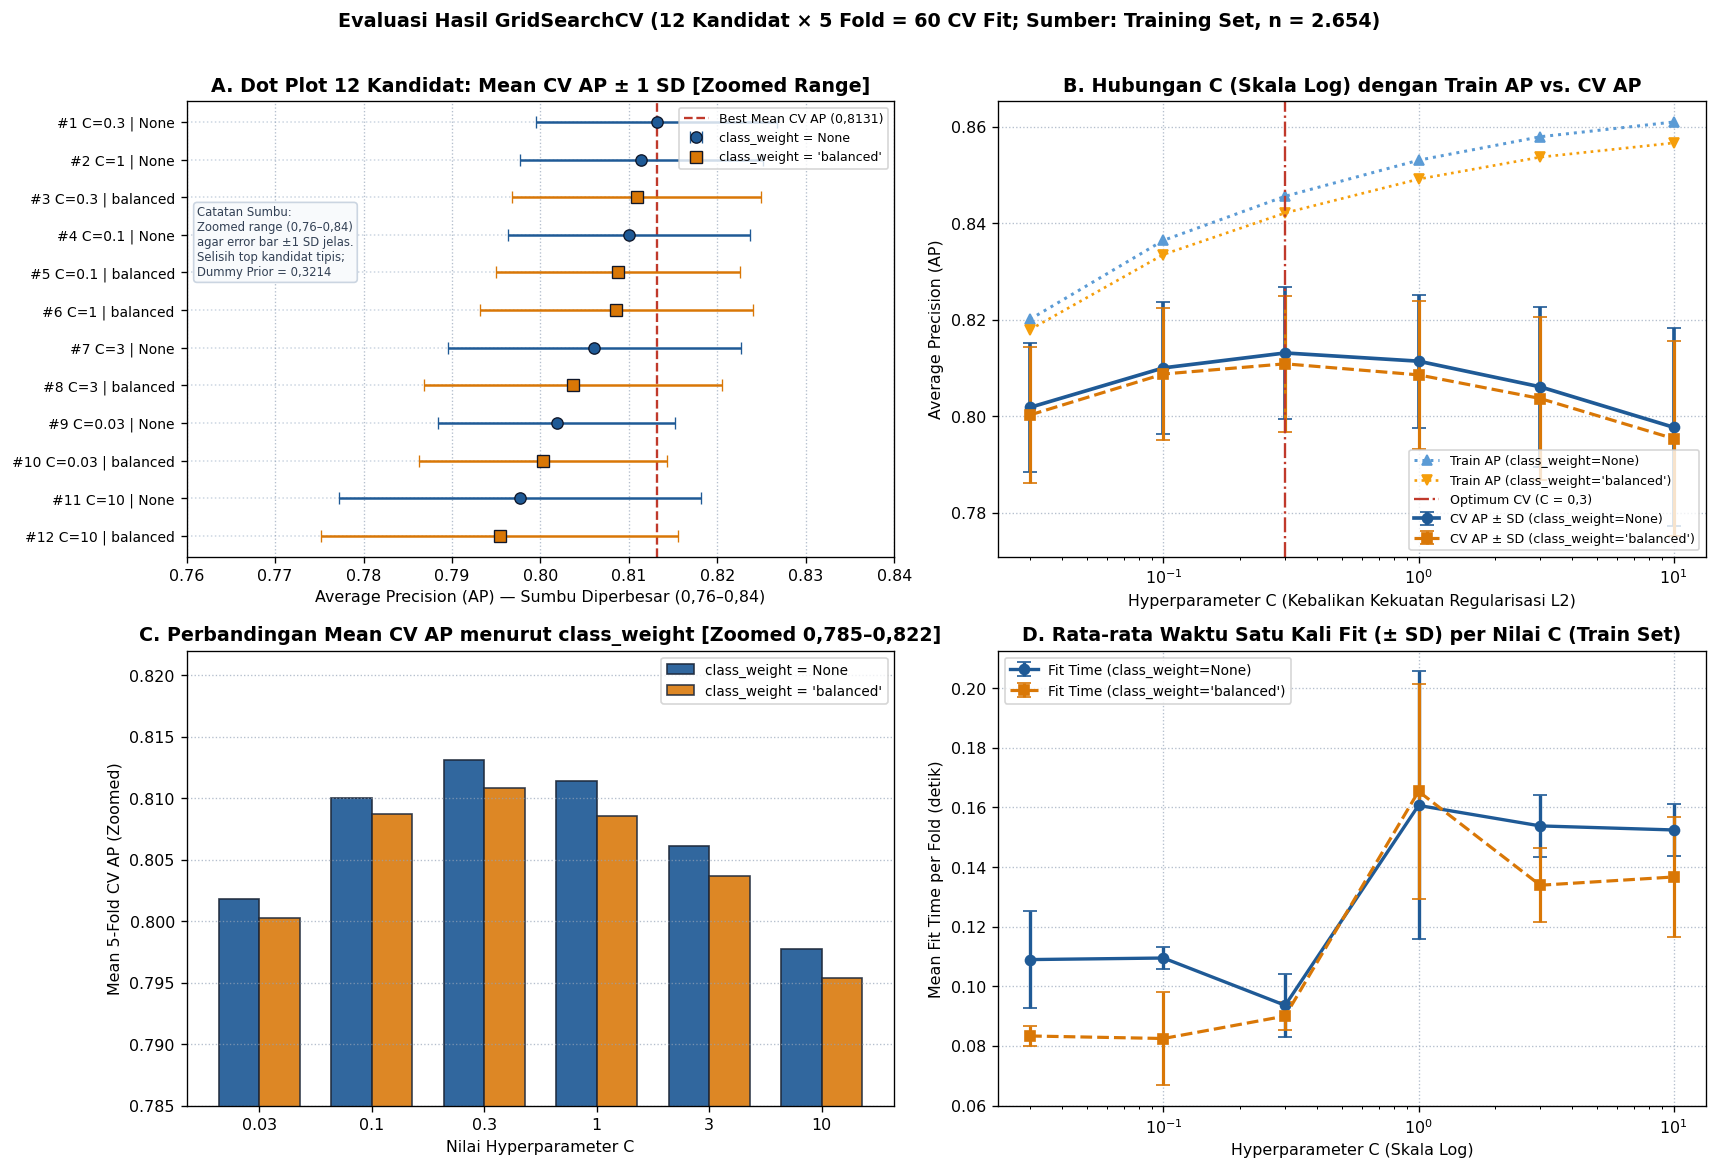

In [22]:
# Bagian E.6 (Visualisasi 1): Grafik Berwarna Analisis Hasil Tuning, Overfitting, & Biaya Fit Time
fig, axes = plt.subplots(2, 2, figsize=(14.4, 9.6))

COL_NONE = "#1f5a96"       # Deep Navy
COL_NONE_TR = "#5b9bd5"    # Soft Blue
COL_BAL = "#d97706"        # Warm Amber
COL_BAL_TR = "#f59e0b"     # Light Amber
COL_OPT = "#c0392b"        # Crimson accent

# Panel A: Dot Plot + Error Bars 12 Konfigurasi (Menghindari Ilusi Batang Terpotong + Keterangan Zoomed Range)
ax_a = axes[0, 0]
label_kand = [f"#{int(r.rank_test_AP)} C={r.param_clf__C:g} | {r.class_weight_str}" for _, r in cv_urut.iterrows()]
y_pos = np.arange(len(cv_urut))
for idx_y, (_, r) in enumerate(cv_urut.iterrows()):
    is_none = r.class_weight_str == "None"
    ax_a.hlines(idx_y, 0.76, float(r.mean_test_AP), color="#cbd5e1", linestyle=":", linewidth=0.9, zorder=1)
    ax_a.errorbar(
        float(r.mean_test_AP), idx_y, xerr=float(r.std_test_AP),
        fmt="o" if is_none else "s",
        color=COL_NONE if is_none else COL_BAL,
        ecolor=COL_NONE if is_none else COL_BAL,
        elinewidth=1.5, capsize=3.5, markersize=6.8,
        markeredgecolor="#0f172a", markeredgewidth=0.8, zorder=3,
        label=("class_weight = None" if idx_y == 0 else ("class_weight = 'balanced'" if idx_y == 2 else None)),
    )
ax_a.invert_yaxis()
ax_a.set_yticks(y_pos)
ax_a.set_yticklabels(label_kand, fontsize=8.3)
ax_a.set_xlim(0.76, 0.84)
ax_a.axvline(float(cv_urut.iloc[0]["mean_test_AP"]), color=COL_OPT, linestyle="--", linewidth=1.4, label="Best Mean CV AP (0,8131)")
ax_a.text(
    0.7612, 3.2,
    "Catatan Sumbu:\nZoomed range (0,76–0,84)\nagar error bar ±1 SD jelas.\nSelisih top kandidat tipis;\nDummy Prior = 0,3214",
    va="center", fontsize=7.0, color="#334155", bbox=dict(boxstyle="round,pad=0.3", facecolor="#f8fafc", edgecolor="#cbd5e1"),
)
ax_a.set_title("A. Dot Plot 12 Kandidat: Mean CV AP ± 1 SD [Zoomed Range]", fontweight="bold")
ax_a.set_xlabel("Average Precision (AP) — Sumbu Diperbesar (0,76–0,84)")
ax_a.legend(loc="upper right", fontsize=7.5)
ax_a.grid(axis="x", linestyle=":", color="#94a3b8", alpha=0.7)

# Panel B: Kurva Train AP vs CV AP terhadap Skala Logaritmik C (Gejala Underfitting & Overfitting)
ax_b = axes[0, 1]
sub_none = cv_results_df[cv_results_df["param_clf__class_weight"].isna() | (cv_results_df["param_clf__class_weight"].astype(str) == "None")].sort_values("param_clf__C")
sub_bal = cv_results_df[cv_results_df["param_clf__class_weight"].astype(str) == "balanced"].sort_values("param_clf__C")
c_vals = sub_none["param_clf__C"].astype(float).to_numpy()

ax_b.plot(c_vals, sub_none["mean_train_AP"], color=COL_NONE_TR, linestyle=":", marker="^", linewidth=1.8, label="Train AP (class_weight=None)")
ax_b.errorbar(c_vals, sub_none["mean_test_AP"], yerr=sub_none["std_test_AP"], color=COL_NONE, linestyle="-", marker="o", linewidth=2.2, capsize=4, label="CV AP ± SD (class_weight=None)")
ax_b.plot(c_vals, sub_bal["mean_train_AP"], color=COL_BAL_TR, linestyle=":", marker="v", linewidth=1.6, label="Train AP (class_weight='balanced')")
ax_b.errorbar(c_vals, sub_bal["mean_test_AP"], yerr=sub_bal["std_test_AP"], color=COL_BAL, linestyle="--", marker="s", linewidth=1.9, capsize=4, label="CV AP ± SD (class_weight='balanced')")
ax_b.axvline(0.3, color=COL_OPT, linestyle="-.", linewidth=1.4, label="Optimum CV (C = 0,3)")
ax_b.set_xscale("log")
ax_b.set_title("B. Hubungan C (Skala Log) dengan Train AP vs. CV AP", fontweight="bold")
ax_b.set_xlabel("Hyperparameter C (Kebalikan Kekuatan Regularisasi L2)")
ax_b.set_ylabel("Average Precision (AP)")
ax_b.legend(loc="lower right", fontsize=7.6)
ax_b.grid(True, linestyle=":", color="#94a3b8", alpha=0.7)

# Panel C: Perbandingan Langsung class_weight=None vs 'balanced' pada Setiap Nilai C
ax_c = axes[1, 0]
x_idx = np.arange(len(c_vals))
w_bar = 0.36
ax_c.bar(x_idx - w_bar / 2, sub_none["mean_test_AP"], width=w_bar, color=COL_NONE, edgecolor="#1e293b", alpha=0.92, label="class_weight = None")
ax_c.bar(x_idx + w_bar / 2, sub_bal["mean_test_AP"], width=w_bar, color=COL_BAL, edgecolor="#1e293b", alpha=0.88, label="class_weight = 'balanced'")
ax_c.set_xticks(x_idx)
ax_c.set_xticklabels([f"{c:g}" for c in c_vals])
ax_c.set_ylim(0.785, 0.822)
ax_c.set_title("C. Perbandingan Mean CV AP menurut class_weight [Zoomed 0,785–0,822]", fontweight="bold")
ax_c.set_xlabel("Nilai Hyperparameter C")
ax_c.set_ylabel("Mean 5-Fold CV AP (Zoomed)")
ax_c.legend(loc="upper right", fontsize=8.2)
ax_c.grid(axis="y", linestyle=":", color="#94a3b8", alpha=0.7)

# Panel D: Biaya Mean Fit Time ± SD per Konfigurasi
ax_d = axes[1, 1]
ax_d.errorbar(c_vals, sub_none["mean_fit_time"], yerr=sub_none["std_fit_time"], color=COL_NONE, linestyle="-", marker="o", linewidth=2.0, capsize=4, label="Fit Time (class_weight=None)")
ax_d.errorbar(c_vals, sub_bal["mean_fit_time"], yerr=sub_bal["std_fit_time"], color=COL_BAL, linestyle="--", marker="s", linewidth=1.9, capsize=4, label="Fit Time (class_weight='balanced')")
ax_d.set_xscale("log")
ax_d.set_title("D. Rata-rata Waktu Satu Kali Fit (± SD) per Nilai C (Train Set)", fontweight="bold")
ax_d.set_xlabel("Hyperparameter C (Skala Log)")
ax_d.set_ylabel("Mean Fit Time per Fold (detik)")
ax_d.legend(loc="upper left", fontsize=8.2)
ax_d.grid(True, linestyle=":", color="#94a3b8", alpha=0.7)

plt.suptitle("Evaluasi Hasil GridSearchCV (12 Kandidat × 5 Fold = 60 CV Fit; Sumber: Training Set, n = 2.654)", fontsize=11.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(LUARAN_VIS_DIR / "01_evaluasi_gridsearch_cv.png", dpi=300, bbox_inches="tight")
plt.show()


**Interpretasi Grafik 1 & Analisis Kritis Keberartian Selisih Skor (Langkah 7 & 8; Sumber: 5-Fold CV *Training Set*, $n = 2.654$):**
* **Pola Regularisasi `C` dan *Overfitting* (Panel A & B):** Kurva validasi silang membentuk pola cekung yang jelas secara metodologis. Pada regularisasi terlalu kuat (`C = 0,03`), model mengalami *underfitting* (`Mean Train AP = 0,8201`; `Mean CV AP = 0,8018 ± 0,0134`). Saat `C` dinaikkan ke **`0,3`**, `Mean CV AP` mencapai puncak tertinggi **`0,8131 ± 0,0136`** (`Mean CV ROC-AUC = 0,8756 ± 0,0137`) dengan celah *train–CV* yang terkendali (`0,8456 - 0,8131 = +0,0324`). Ketika regularisasi dilemahkan lebih jauh ke `C = 3,0` dan `C = 10,0`, `Mean Train AP` terus menanjak hingga `0,8609`, tetapi `Mean CV AP` justru turun ke `0,7977 ± 0,0205` (celah *train–CV* melebar hampir dua kali lipat menjadi `+0,0632` dan simpangan baku antar-fold membesar ke `0,0205`). Pada Panel D, kandidat `C = 10,0` juga mencatat rata-rata waktu `fit` yang lebih lama (sekitar `1,3–1,6` kali kandidat terbaik `C = 0,3, None`, bergantung beban CPU saat eksekusi); namun karena jumlah iterasi `n_iter_` tidak direkam untuk setiap kandidat di seluruh 60 lipatan CV, durasi yang lebih lambat tersebut dicatat sebagai temuan empiris tanpa memastikan bahwa penyebab tunggalnya adalah jumlah iterasi `lbfgs`.
* **Pengaruh `class_weight` (Panel C):** Di seluruh enam nilai `C`, `class_weight = None` secara konsisten melampaui `class_weight = "balanced"` sebesar `+0,0013` hingga `+0,0028` poin `AP`. Pemberian bobot kelas seimbang mengubah kemiringan fungsi kerugian pada sampel batas tanpa memperbaiki ketepatan urutan peringkat kelas positif.
* **Apakah perbedaan skor antarkonfigurasi teratas cukup berarti? (Batasan & Penjelasan Alternatif):** Secara jujur, selisih `Mean CV AP` antara peringkat ke-1 (`C = 0,3, None`: `0,8131`) dan konfigurasi P11 peringkat ke-2 (`C = 1,0, None`: `0,8114`) hanya sebesar **`+0,0017`** (`+0,17` poin persentase), yang jauh lebih kecil dibandingkan simpangan baku antar-fold (`~0,0136`). Pemeriksaan *per-fold* menunjukkan `C = 0,3` unggul tipis pada 3 lipatan (Fold 1, 3, dan 5), sedangkan `C = 1,0` sedikit lebih tinggi pada 2 lipatan (Fold 2 dan 4). Perhatikan pula bahwa Panel A disajikan sebagai *dot plot* dengan rentang sumbu diperbesar (*zoomed range* `0,76–0,84`) semata-mata agar lebar *error bar* `±1 SD` terlihat jelas—tumpang-tindih *error bar* tersebut justru menegaskan betapa rapatnya lima kandidat teratas. Dengan demikian, **tidak boleh diklaim terdapat peningkatan signifikan secara statistik**; keunggulan `C = 0,3` bersifat **sangat tipis dan inkremental**, namun tetap rasional dipilih berdasarkan kriteria objektif `refit='AP'` yang telah ditetapkan sebelum pencarian.


In [23]:
# Bagian E.7 (Kode): Pemeriksaan best_params_, best_score_, dan Parameter Terpelajar pada best_estimator_ (Langkah 9)
best_params_terpilih = search.best_params_
best_score_cv_ap = float(search.best_score_)
best_estimator_p12 = search.best_estimator_

clf_sebelum = pipeline_sebelum_tuning.named_steps["clf"]
clf_terbaik = best_estimator_p12.named_steps["clf"]
norm_l2_sebelum = float(np.linalg.norm(clf_sebelum.coef_))
norm_l2_terbaik = float(np.linalg.norm(clf_terbaik.coef_))

nama_fitur_ohe = best_estimator_p12.named_steps["prep"].get_feature_names_out()
seri_koef_best = pd.Series(clf_terbaik.coef_.ravel(), index=nama_fitur_ohe)
top_pos_koef = seri_koef_best.sort_values(ascending=False).head(5)
top_neg_koef = seri_koef_best.sort_values(ascending=True).head(5)

print("=== RINGKASAN HASIL PEMILIHAN GRIDSEARCHCV ===")
print(f"best_params_                     : {best_params_terpilih}")
print(f"best_score_ (Mean 5-Fold CV AP)  : {best_score_cv_ap:.4f} (tepatnya {best_score_cv_ap:.6f})")
print(f"Dimensi parameter coef_          : {clf_terbaik.coef_.shape} | intercept_ = {float(clf_terbaik.intercept_[0]):.4f}")
print(f"Norma L2 vektor coef_ (||w||_2)  : Sebelum tuning (C=1.0) = {norm_l2_sebelum:.4f} -> Best estimator (C=0.3) = {norm_l2_terbaik:.4f} (menyusut {(1 - norm_l2_terbaik/norm_l2_sebelum)*100:.1f}%)")
print(f"Jumlah iterasi konvergensi lbfgs : Sebelum tuning = {int(clf_sebelum.n_iter_[0])} iterasi | Best estimator = {int(clf_terbaik.n_iter_[0])} iterasi")

df_koef_ringkas = pd.DataFrame({
    "5 Fitur Pendorong Risiko Dropout Tertinggi (coef_ > 0)": [f"{k} ({v:+.4f})" for k, v in top_pos_koef.items()],
    "5 Fitur Penahan Risiko Dropout Terkuat (coef_ < 0)": [f"{k} ({v:+.4f})" for k, v in top_neg_koef.items()],
})
display(df_koef_ringkas)


=== RINGKASAN HASIL PEMILIHAN GRIDSEARCHCV ===
best_params_                     : {'clf__C': 0.3, 'clf__class_weight': None}
best_score_ (Mean 5-Fold CV AP)  : 0.8131 (tepatnya 0.813109)
Dimensi parameter coef_          : (1, 213) | intercept_ = -1.3377
Norma L2 vektor coef_ (||w||_2)  : Sebelum tuning (C=1.0) = 6.4629 -> Best estimator (C=0.3) = 4.3923 (menyusut 32.0%)
Jumlah iterasi konvergensi lbfgs : Sebelum tuning = 76 iterasi | Best estimator = 64 iterasi


,5 Fitur Pendorong Risiko Dropout Tertinggi (coef_ > 0),5 Fitur Penahan Risiko Dropout Terkuat (coef_ < 0)
0,nom__Course_9853 (+1.0700),num__Curricular units 1st sem (approved) (-2.2001)
1,nom__Course_9130 (+0.8163),nom__Mother's qualification_2 (-0.9736)
2,nom__Mother's qualification_34 (+0.8114),nom__Mother's occupation_191 (-0.6775)
3,nom__Mother's occupation_0 (+0.8055),nom__Course_171 (-0.6402)
4,num__Curricular units 1st sem (enrolled) (+0.7684),bin__Scholarship holder (-0.5969)


**Makna `best_params_`, `best_score_`, dan `best_estimator_`:**
* **`best_params_` (`{'clf__C': 0.3, 'clf__class_weight': None}`):** Dictionary yang memuat pasangan nilai *hyperparameter* peraih skor rata-rata validasi silang tertinggi berdasarkan metrik `refit="AP"`.
* **`best_score_` (`0,8131`):** Rata-rata skor `Average Precision` dari kelima lipatan validasi di dalam *Training Set* untuk kombinasi `best_params_` *(bukan skor Validation Set luar maupun Test Set)*.
* **`best_estimator_`:** Objek `Pipeline` utuh (`ColumnTransformer` + `LogisticRegression(C=0.3, class_weight=None, l1_ratio=0.0)`) yang telah dilatih ulang satu kali (`refit=True`) pada seluruh `2.654` observasi *Training Set* (`28` fitur mentah $\rightarrow$ `213` kolom tertransformasi). Pada parameter yang dipelajari, norma Euclidean vektor koefisien $\|\mathbf{w}\|_2$ menyusut sebesar **`32,0%`** (dari **`6,4629`** pada `C = 1,0` menjadi **`4,3923`** pada `C = 0,3`), sementara fitur kurikuler `Curricular units 1st sem (approved)` tetap menjadi sinyal penahan *dropout* terkuat. Perlu ditegaskan bahwa **penyusutan norma koefisien ini merupakan konsekuensi matematis langsung dari penguatan penalti regularisasi $L_2$, bukan bukti tunggal bahwa model lebih baik**; kelayakan model tetap harus dinilai dari metrik validasi dan pengujian.


---
## BAGIAN F — EVALUASI *VALIDATION SET*, KETERKAITAN KALIBRASI DENGAN P11, DAN PEMILIHAN *THRESHOLD* OPERASIONAL

Sesuai kesinambungan metodologis dengan Pertemuan 11:
1. `GridSearchCV` pada Bagian E mengoptimalkan **kemampuan pengurutan peringkat probabilitas *native*** berdasarkan `Average Precision (AP)`, bukan mengoptimalkan `Brier Score` atau `ECE`.
2. Oleh sebab itu, pada tahap terpisah ini diperiksa kualitas kalibrasi probabilitas pada *Validation Set* (`n = 885`), baik untuk **probabilitas *native*** maupun setelah dibungkus **`CalibratedClassifierCV(method="isotonic", cv=cv_5fold)`** di atas seluruh `Pipeline` (sehingga setiap lipatan kalibrasi di dalam *Training Set* melakukan `fit` prapemrosesan secara mandiri tanpa *leakage*, menambah `5` proses `fit` per model).
3. Karena perubahan nilai `C` dari `1,0` menjadi `0,3` mengubah penyebaran probabilitas prediksi, **ambang `0,3483` dari P11 tidak boleh langsung dipakai ulang**: setiap model dievaluasi kembali pada *Validation Set* menggunakan matriks biaya simulasi `2 × 2` (`FP = 1`, `FN = 4` satuan relatif) dan skenario simulasi kapasitas `<= 35%` (`<= 309` mahasiswa di *Validation Set*) pada seluruh titik probabilitas unik ditambah batas atas `np.nextafter(max, inf)`.


In [24]:
# Bagian F.1 - F.4 (Kode): Audit Kalibrasi (Native vs Isotonic CV=5) & Penentuan Ulang Threshold pada Validation Set
def hitung_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    batas = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n_tot = len(y_true)
    for i in range(n_bins):
        lo, hi = batas[i], batas[i + 1]
        mask = (y_prob >= lo) & (y_prob < hi) if i < n_bins - 1 else (y_prob >= lo) & (y_prob <= hi)
        jml = int(np.sum(mask))
        if jml > 0:
            ece += (jml / n_tot) * abs(float(np.mean(y_prob[mask])) - float(np.mean(y_true[mask])))
    return float(ece)


def evaluasi_threshold_lengkap(y_true: np.ndarray, y_prob: np.ndarray, thr: float, c_fp: int = 1, c_fn: int = 4) -> dict:
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_obs = len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = (2.0 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    return {
        "Threshold": float(thr),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "Accuracy": round((tp + tn) / n_obs, 4),
        "Precision": round(prec, 4), "Recall": round(rec, 4),
        "Specificity": round(spec, 4), "F1": round(f1, 4),
        "Flagged": int(tp + fp),
        "Flagged_Pct": round((tp + fp) / n_obs * 100, 2),
        "Error_Cost_1_4": int(c_fp * fp + c_fn * fn),
    }


def cari_threshold_optimal_validasi(y_true: np.ndarray, y_prob: np.ndarray, persen_kapasitas: float = 35.0):
    batas_mhs = int(np.floor(len(y_true) * persen_kapasitas / 100.0))
    kandidat_eksak = np.append(np.sort(np.unique(y_prob)), float(np.nextafter(y_prob.max(), np.inf)))
    df_eksak = pd.DataFrame([evaluasi_threshold_lengkap(y_true, y_prob, float(t)) for t in kandidat_eksak])
    min_tanpa_batas = df_eksak.sort_values(["Error_Cost_1_4", "Flagged"]).iloc[0].to_dict()
    min_eksak_kap = df_eksak[df_eksak["Flagged"] <= batas_mhs].sort_values(["Error_Cost_1_4", "Flagged"]).iloc[0].to_dict()

    grid_001 = np.round(np.arange(0.01, 1.00, 0.01), 2)
    df_grid = pd.DataFrame([evaluasi_threshold_lengkap(y_true, y_prob, float(t)) for t in grid_001])
    min_grid_kap = df_grid[df_grid["Flagged"] <= batas_mhs].sort_values(["Error_Cost_1_4", "Flagged"]).iloc[0].to_dict()
    return min_tanpa_batas, min_eksak_kap, min_grid_kap, df_eksak, df_grid


# Matriks biaya 2x2 eksplisit skenario acuan P11/P12 (satuan biaya relatif simulasi)
df_matriks_biaya_p12 = pd.DataFrame([
    {"Aktual / Prediksi": "Non-Dropout (Kelas 0)", "Prediksi 0": "TN = 0", "Prediksi 1": "FP = 1"},
    {"Aktual / Prediksi": "Dropout (Kelas 1)", "Prediksi 0": "FN = 4", "Prediksi 1": "TP = 0"},
])
print("=== MATRIKS BIAYA KESALAHAN 2 x 2 (SATUAN BIAYA RELATIF SIMULASI, BUKAN NOMINAL KERUGIAN AKTUAL) ===")
display(df_matriks_biaya_p12)

# Pelatihan kalibrasi Isotonic (CV=5 di dalam Training Set) secara terpisah untuk model P11 & Best Estimator P12
t0_iso_pre = time.perf_counter()
model_sebelum_isotonic = CalibratedClassifierCV(
    estimator=bangun_pipeline_logreg(c_val=1.0, cw_val=None),
    method="isotonic",
    cv=cv_5fold,
).fit(X_train, y_train)
durasi_iso_sebelum = time.perf_counter() - t0_iso_pre

t0_iso_best = time.perf_counter()
model_best_isotonic = CalibratedClassifierCV(
    estimator=clone(best_estimator_p12),
    method="isotonic",
    cv=cv_5fold,
).fit(X_train, y_train)
durasi_iso_best = time.perf_counter() - t0_iso_best

print(f"Waktu tambahan kalibrasi Isotonic (masing-masing 5 fit di Train Set): Sebelum Tuning = {durasi_iso_sebelum:.4f}s | Best Estimator = {durasi_iso_best:.4f}s")

kandidat_model_val = [
    ("1. Baseline: DummyClassifier (prior)", pipeline_dummy_prior, True),
    ("2a. Sebelum Tuning — Native (C=1.0, None)", pipeline_sebelum_tuning, False),
    ("3a. Best Estimator P12 — Native (C=0.3, None)", best_estimator_p12, False),
    ("2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)", model_sebelum_isotonic, False),
    ("3b. Best Estimator P12 + Isotonic CV=5 (C=0.3)", model_best_isotonic, False),
]

proba_val_semua = {}
threshold_terkunci_val = {}
baris_val_default050 = []
baris_val_operasional = []
kurva_grid_val_map = {}

for nama_m, obj_m, is_dummy in kandidat_model_val:
    pv = obj_m.predict_proba(X_val)[:, 1]
    proba_val_semua[nama_m] = pv
    ap_v = round(average_precision_score(y_val, pv), 4)
    auc_v = round(roc_auc_score(y_val, pv), 4)
    brier_v = round(brier_score_loss(y_val, pv), 4)
    ece10_v = round(hitung_ece(y_val, pv, 10), 4)
    ece5_v = round(hitung_ece(y_val, pv, 5), 4)

    ev_050 = evaluasi_threshold_lengkap(y_val, pv, 0.50)
    min_unc, min_kap, min_grid, _, df_g = cari_threshold_optimal_validasi(y_val, pv, persen_kapasitas=35.0)
    kurva_grid_val_map[nama_m] = df_g

    thr_op = 0.50 if is_dummy else float(min_kap["Threshold"])
    threshold_terkunci_val[nama_m] = thr_op
    ev_op = evaluasi_threshold_lengkap(y_val, pv, thr_op)

    info_umum = {"Model": nama_m, "Val ROC-AUC": auc_v, "Val AP": ap_v, "Val Brier": brier_v, "Val ECE-10": ece10_v}
    baris_val_default050.append({
        **info_umum,
        "Threshold": 0.5000,
        "TP": ev_050["TP"], "FP": ev_050["FP"], "TN": ev_050["TN"], "FN": ev_050["FN"],
        "Precision": ev_050["Precision"], "Recall": ev_050["Recall"], "Specificity": ev_050["Specificity"], "F1": ev_050["F1"],
        "Flagged (%)": f"{ev_050['Flagged']} ({ev_050['Flagged_Pct']:.2f}%)",
        "Biaya (1:4)": ev_050["Error_Cost_1_4"],
    })
    baris_val_operasional.append({
        **info_umum,
        "t* Eksak (<=35%)": round(thr_op, 4),
        "Alt Grid 0.01": "-" if is_dummy else f"{min_grid['Threshold']:.2f} (Cost={min_grid['Error_Cost_1_4']})",
        "TP": ev_op["TP"], "FP": ev_op["FP"], "TN": ev_op["TN"], "FN": ev_op["FN"],
        "Precision": ev_op["Precision"], "Recall": ev_op["Recall"], "Specificity": ev_op["Specificity"], "F1": ev_op["F1"],
        "Flagged (%)": f"{ev_op['Flagged']} ({ev_op['Flagged_Pct']:.2f}%)",
        "Biaya (1:4)": ev_op["Error_Cost_1_4"],
    })

df_val_050 = pd.DataFrame(baris_val_default050)
df_val_op = pd.DataFrame(baris_val_operasional)
df_val_050.to_csv(LUARAN_TAB_DIR / "07a_perbandingan_validasi_threshold_050.csv", index=False)
df_val_op.to_csv(LUARAN_TAB_DIR / "07b_perbandingan_validasi_threshold_operasional.csv", index=False)

print("\n=== TABEL F.1: PERBANDINGAN PADA VALIDATION SET (n = 885) — THRESHOLD DEFAULT t = 0,50 ===")
display(df_val_050)
print("\n=== TABEL F.2: PERBANDINGAN PADA VALIDATION SET (n = 885) — THRESHOLD OPERASIONAL TERKENDALA SIMULASI KAPASITAS <= 35% ===")
display(df_val_op)


=== MATRIKS BIAYA KESALAHAN 2 x 2 (SATUAN BIAYA RELATIF SIMULASI, BUKAN NOMINAL KERUGIAN AKTUAL) ===


,Aktual / Prediksi,Prediksi 0,Prediksi 1
0,Non-Dropout (Kelas 0),TN = 0,FP = 1
1,Dropout (Kelas 1),FN = 4,TP = 0


Waktu tambahan kalibrasi Isotonic (masing-masing 5 fit di Train Set): Sebelum Tuning = 0.4387s | Best Estimator = 0.3546s

=== TABEL F.1: PERBANDINGAN PADA VALIDATION SET (n = 885) — THRESHOLD DEFAULT t = 0,50 ===


,Model,Val ROC-AUC,Val AP,Val Brier,Val ECE-10,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged (%),Biaya (1:4)
0,1. Baseline: DummyClassifier (prior),0.5000,0.3209,0.2179,0.0005,0.5000,0,0,601,284,0.0000,0.0000,1.0000,0.0000,0 (0.00%),1136
1,"2a. Sebelum Tuning — Native (C=1.0, None)",0.8852,0.8393,0.1142,0.0444,0.5000,201,46,555,83,0.8138,0.7077,0.9235,0.7571,247 (27.91%),378
2,"3a. Best Estimator P12 — Native (C=0.3, None)",0.8847,0.8396,0.1140,0.0346,0.5000,198,45,556,86,0.8148,0.6972,0.9251,0.7514,243 (27.46%),389
3,2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0),0.8868,0.8408,0.1136,0.0270,0.5000,197,46,555,87,0.8107,0.6937,0.9235,0.7476,243 (27.46%),394
4,3b. Best Estimator P12 + Isotonic CV=5 (C=0.3),0.8835,0.8364,0.1148,0.0310,0.5000,203,51,550,81,0.7992,0.7148,0.9151,0.7546,254 (28.70%),375



=== TABEL F.2: PERBANDINGAN PADA VALIDATION SET (n = 885) — THRESHOLD OPERASIONAL TERKENDALA SIMULASI KAPASITAS <= 35% ===


,Model,Val ROC-AUC,Val AP,Val Brier,Val ECE-10,t* Eksak (<=35%),Alt Grid 0.01,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged (%),Biaya (1:4)
0,1. Baseline: DummyClassifier (prior),0.5000,0.3209,0.2179,0.0005,0.5000,-,0,0,601,284,0.0000,0.0000,1.0000,0.0000,0 (0.00%),1136
1,"2a. Sebelum Tuning — Native (C=1.0, None)",0.8852,0.8393,0.1142,0.0444,0.3580,0.36 (Cost=354.0),219,90,511,65,0.7087,0.7711,0.8502,0.7386,309 (34.92%),350
2,"3a. Best Estimator P12 — Native (C=0.3, None)",0.8847,0.8396,0.1140,0.0346,0.3515,0.35 (Cost=345.0),220,89,512,64,0.7120,0.7746,0.8519,0.7420,309 (34.92%),345
3,2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0),0.8868,0.8408,0.1136,0.0270,0.3483,0.34 (Cost=344.0),220,86,515,64,0.7190,0.7746,0.8569,0.7458,306 (34.58%),342
4,3b. Best Estimator P12 + Isotonic CV=5 (C=0.3),0.8835,0.8364,0.1148,0.0310,0.3794,0.37 (Cost=355.0),215,76,525,69,0.7388,0.7570,0.8735,0.7478,291 (32.88%),352


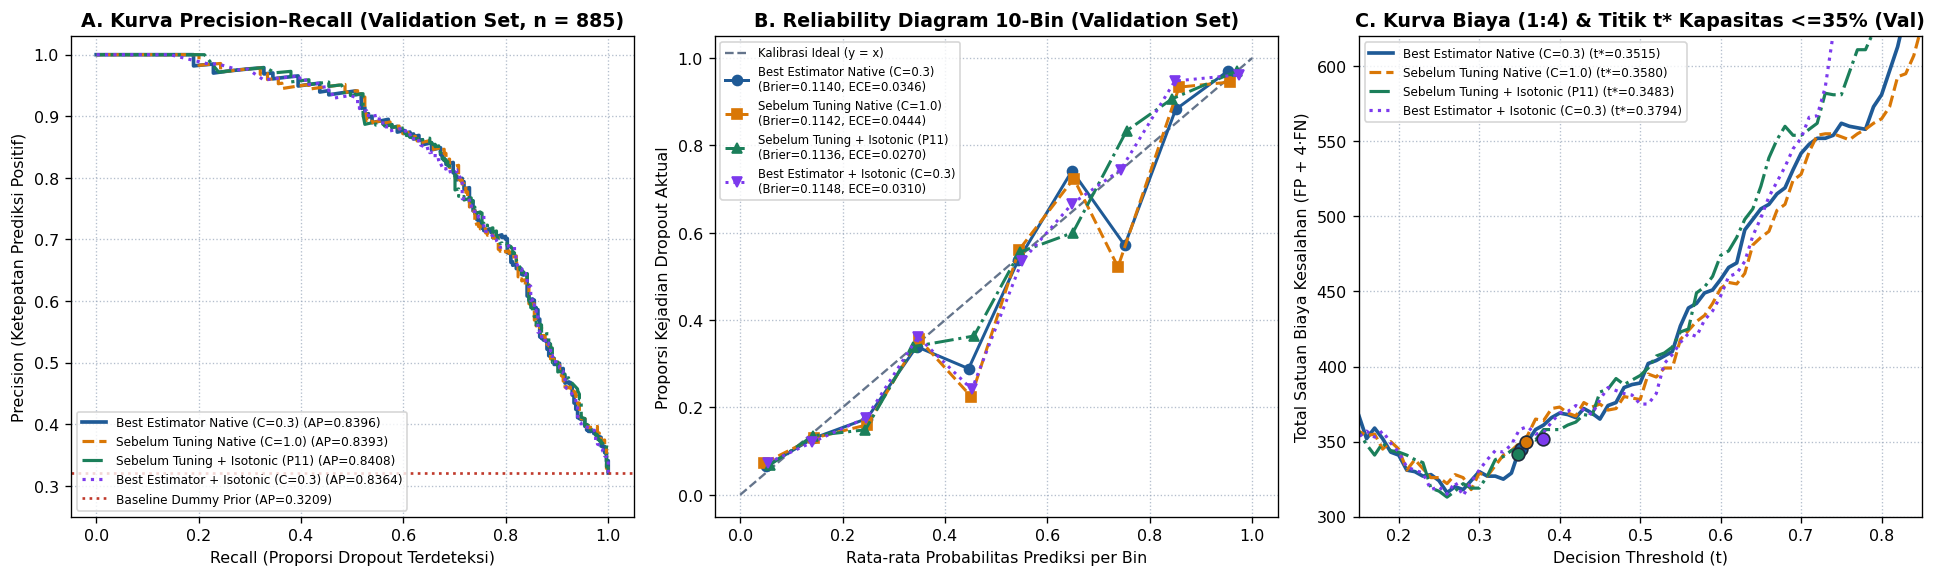

In [25]:
# Bagian F.4 (Visualisasi 2): Grafik Berwarna Kurva PR, Reliability Diagram, dan Kurva Biaya Threshold pada Validation Set
fig, axes = plt.subplots(1, 3, figsize=(16.2, 4.9))
prev_val = float(y_val.mean())

seri_visual_val = [
    ("Best Estimator Native (C=0.3)", "3a. Best Estimator P12 — Native (C=0.3, None)", "#1f5a96", "-", "o", 2.2),
    ("Sebelum Tuning Native (C=1.0)", "2a. Sebelum Tuning — Native (C=1.0, None)", "#d97706", "--", "s", 1.9),
    ("Sebelum Tuning + Isotonic (P11)", "2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)", "#1b7f5a", "-.", "^", 1.9),
    ("Best Estimator + Isotonic (C=0.3)", "3b. Best Estimator P12 + Isotonic CV=5 (C=0.3)", "#7c3aed", ":", "v", 1.9),
]

# Panel A: Precision-Recall Curve Validation
ax_pr = axes[0]
for lbl_s, key_s, col_s, ls_s, _, lw_s in seri_visual_val:
    pv_s = proba_val_semua[key_s]
    prec_s, rec_s, _ = precision_recall_curve(y_val, pv_s)
    ap_s = average_precision_score(y_val, pv_s)
    ax_pr.plot(rec_s, prec_s, color=col_s, linestyle=ls_s, linewidth=lw_s, label=f"{lbl_s} (AP={ap_s:.4f})")
ax_pr.axhline(prev_val, color="#c0392b", linestyle=":", linewidth=1.6, label=f"Baseline Dummy Prior (AP={prev_val:.4f})")
ax_pr.set_ylim(0.25, 1.03)
ax_pr.set_title("A. Kurva Precision–Recall (Validation Set, n = 885)", fontweight="bold")
ax_pr.set_xlabel("Recall (Proporsi Dropout Terdeteksi)")
ax_pr.set_ylabel("Precision (Ketepatan Prediksi Positif)")
ax_pr.legend(loc="lower left", fontsize=7.3)
ax_pr.grid(True, linestyle=":", color="#94a3b8", alpha=0.7)

# Panel B: Reliability Diagram Validation
ax_cal = axes[1]
ax_cal.plot([0, 1], [0, 1], color="#64748b", linestyle="--", linewidth=1.4, label="Kalibrasi Ideal (y = x)")
for lbl_s, key_s, col_s, ls_s, mk_s, lw_s in seri_visual_val:
    pv_s = proba_val_semua[key_s]
    pt_s, pp_s = calibration_curve(y_val, pv_s, n_bins=10, strategy="uniform")
    br_s = brier_score_loss(y_val, pv_s)
    ec_s = hitung_ece(y_val, pv_s, 10)
    ax_cal.plot(pp_s, pt_s, color=col_s, linestyle=ls_s, marker=mk_s, linewidth=1.8, label=f"{lbl_s}\n(Brier={br_s:.4f}, ECE={ec_s:.4f})")
ax_cal.set_title("B. Reliability Diagram 10-Bin (Validation Set)", fontweight="bold")
ax_cal.set_xlabel("Rata-rata Probabilitas Prediksi per Bin")
ax_cal.set_ylabel("Proporsi Kejadian Dropout Aktual")
ax_cal.legend(loc="upper left", fontsize=7.0)
ax_cal.grid(True, linestyle=":", color="#94a3b8", alpha=0.7)

# Panel C: Kurva Biaya Kesalahan (1:4) & Pergeseran Threshold Optimal <= 35%
ax_cost = axes[2]
for lbl_s, key_s, col_s, ls_s, _, lw_s in seri_visual_val:
    df_g_s = kurva_grid_val_map[key_s]
    thr_op_s = threshold_terkunci_val[key_s]
    ax_cost.plot(df_g_s["Threshold"], df_g_s["Error_Cost_1_4"], color=col_s, linestyle=ls_s, linewidth=lw_s, label=f"{lbl_s} (t*={thr_op_s:.4f})")
    ev_star = evaluasi_threshold_lengkap(y_val, proba_val_semua[key_s], thr_op_s)
    ax_cost.scatter([thr_op_s], [ev_star["Error_Cost_1_4"]], color=col_s, edgecolor="#1e293b", s=58, zorder=5)

ax_cost.set_xlim(0.15, 0.85)
ax_cost.set_ylim(300, 620)
ax_cost.set_title("C. Kurva Biaya (1:4) & Titik t* Kapasitas <=35% (Val)", fontweight="bold")
ax_cost.set_xlabel("Decision Threshold (t)")
ax_cost.set_ylabel("Total Satuan Biaya Kesalahan (FP + 4·FN)")
ax_cost.legend(loc="upper left", fontsize=7.2)
ax_cost.grid(True, linestyle=":", color="#94a3b8", alpha=0.7)

plt.tight_layout()
plt.savefig(LUARAN_VIS_DIR / "02_validasi_kalibrasi_dan_threshold.png", dpi=300, bbox_inches="tight")
plt.show()


**Interpretasi Grafik 2 & Temuan Metodologis Penting pada *Validation Set* (Sumber: *Validation Set*, $n = 885$):**
1. **Penyusutan Regularisasi `C = 0,3` Secara Alami Memperbaiki Kalibrasi *Native*:** Pada model *native* tanpa kalibrator pascapelatihan, penurunan `C` dari `1,0` menjadi `0,3` memperbaiki `Val AP` tipis (`0,8393` $\rightarrow$ `0,8396`), menurunkan `Brier Score` (`0,1142` $\rightarrow$ `0,1140`), mengurangi `ECE 10-bin` sebesar **`22,1%`** (`0,0444` $\rightarrow$ `0,0346`), dan menurunkan total biaya kesalahan terkendala kapasitas `<= 35%` dari `350` satuan (`t* = 0,3580`) menjadi **`345` satuan (`t* = 0,3515`; grid `0,35` juga `345` satuan)**. Hal ini terjadi karena penalti $L_2$ yang lebih kuat meredam probabilitas *overconfident* di dekat `0` dan `1`.
2. **Interaksi antara Regularisasi Kuat dan Kalibrasi Isotonic Non-Parametrik (Batasan & Penjelasan Alternatif):** Pada konfigurasi pra-*tuning* (`C = 1,0`), kalibrasi `Isotonic Regression` sangat bermanfaat (`Val AP = 0,8408`, `Brier = 0,1136`, `ECE = 0,0270`, `Biaya = 342` pada `t* = 0,3483`). Sebaliknya, ketika `Isotonic Regression` dipasang di atas `best_estimator_` yang sudah terregularisasi kuat (`C = 0,3`), fungsi tangga non-parametrik pada lipatan internal justru menghasilkan cukup banyak skor kembar (*step ties*) yang sedikit menurunkan `Val AP` ke `0,8364`, menaikkan `Brier Score` ke `0,1148`, dan menggeser batas kapasitas `<= 35%` ke `t* = 0,3794` (`Biaya = 352`).
3. **Keputusan Penguncian Sebelum Membuka *Test Set*:** Berdasarkan bukti murni *Training CV* dan *Validation Set* (tanpa melihat *Test Set*), **`Best Estimator P12 — Native (C = 0,3, class_weight = None)` dengan ambang operasional `t* = 0,3515`** dikunci sebagai estimator hasil *tuning* utama (`best_estimator_` langsung dari `GridSearchCV`), sementara varian `Sebelum Tuning + Isotonic (P11: t* = 0,3483)` dan `Best Estimator + Isotonic (t* = 0,3794)` tetap disertakan berdampingan pada evaluasi akhir agar perbandingan dengan P11 berlangsung transparan penuh.


---
## BAGIAN G — PENGUNCIAN KONFIGURASI, EVALUASI FINAL SATU KALI PADA *TEST SET*, DAN JUSTIFIKASI ARTIKEL UAS

Seluruh *hyperparameter*, pilihan kalibrasi, dan nilai *threshold* operasional telah dikunci menggunakan *Training Set* dan *Validation Set*. Pada sel berikut, matriks fitur dan label `Test Set` (`n = 885`) dibuka **hanya satu kali pada tahap akhir Pertemuan 12** untuk menilai generalisasi secara adil pada:
1. **Baseline (`DummyClassifier(strategy="prior")`)**,
2. **Model *Logistic Regression* Sebelum Tuning (`C = 1,0`, `class_weight = None` — baik *Native* maupun *Isotonic P11*)**, dan
3. **`Best Estimator` Hasil `GridSearchCV` (`C = 0,3`, `class_weight = None` — baik *Native* maupun *Isotonic*)**.


In [26]:
# Bagian G.1 & G.2 (Kode): Penguncian Konfigurasi & Evaluasi Akhir Satu Tahap pada Test Set (Langkah 10 & 11)
KONFIGURASI_TERKUNCI_P12 = {
    "estimator_utama_p12": "Best Estimator GridSearchCV — LogisticRegression(C=0.3, class_weight=None) di dalam Pipeline",
    "best_params_cv": best_params_terpilih,
    "best_score_cv_ap": round(best_score_cv_ap, 4),
    "threshold_operasional_best_native": threshold_terkunci_val["3a. Best Estimator P12 — Native (C=0.3, None)"],
    "threshold_operasional_sebelum_native": threshold_terkunci_val["2a. Sebelum Tuning — Native (C=1.0, None)"],
    "threshold_operasional_p11_isotonic": threshold_terkunci_val["2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"],
    "threshold_operasional_best_isotonic": threshold_terkunci_val["3b. Best Estimator P12 + Isotonic CV=5 (C=0.3)"],
}
for k_lock, v_lock in KONFIGURASI_TERKUNCI_P12.items():
    print(f"{k_lock:38s}: {v_lock}")

# Pembukaan satu kali Test Set pada tahap evaluasi final P12
df_test_final = df_uci.iloc[idx_test_locked].reset_index(drop=True)
X_test_final = df_test_final[fitur_konservatif_28].copy()
y_test_final = df_test_final["label_dropout"].to_numpy()
n_test_pos = int((y_test_final == 1).sum())
n_test_neg = int((y_test_final == 0).sum())
print(f"\nTest Set dievaluasi (satu tahap final): n = {len(y_test_final)} (Dropout = {n_test_pos} [{n_test_pos/len(y_test_final)*100:.2f}%], Non-Dropout = {n_test_neg} [{n_test_neg/len(y_test_final)*100:.2f}%])")

baris_test_050 = []
baris_test_op = []
proba_test_semua = {}
cm_test_op_semua = {}

for nama_m, obj_m, _ in kandidat_model_val:
    pt = obj_m.predict_proba(X_test_final)[:, 1]
    proba_test_semua[nama_m] = pt
    thr_locked = threshold_terkunci_val[nama_m]

    auc_t = round(roc_auc_score(y_test_final, pt), 4)
    ap_t = round(average_precision_score(y_test_final, pt), 4)
    prec_curve_t, rec_curve_t, _ = precision_recall_curve(y_test_final, pt)
    trap_t = round(auc(rec_curve_t, prec_curve_t), 4)
    brier_t = round(brier_score_loss(y_test_final, pt), 4)
    ece10_t = round(hitung_ece(y_test_final, pt, 10), 4)

    ev_t050 = evaluasi_threshold_lengkap(y_test_final, pt, 0.50)
    ev_top = evaluasi_threshold_lengkap(y_test_final, pt, thr_locked)
    cm_test_op_semua[nama_m] = ev_top

    meta_t = {"Model": nama_m, "Test ROC-AUC": auc_t, "Test AP": ap_t, "Test Trap PR-AUC": trap_t, "Test Brier": brier_t, "Test ECE-10": ece10_t}
    baris_test_050.append({
        **meta_t,
        "Threshold": 0.5000,
        "TP": ev_t050["TP"], "FP": ev_t050["FP"], "TN": ev_t050["TN"], "FN": ev_t050["FN"],
        "Precision": ev_t050["Precision"], "Recall": ev_t050["Recall"], "Specificity": ev_t050["Specificity"], "F1": ev_t050["F1"],
        "Flagged (%)": f"{ev_t050['Flagged']} ({ev_t050['Flagged_Pct']:.2f}%)",
        "Biaya (1:4)": ev_t050["Error_Cost_1_4"],
    })
    baris_test_op.append({
        **meta_t,
        "Threshold Val Terkunci": round(thr_locked, 4),
        "TP": ev_top["TP"], "FP": ev_top["FP"], "TN": ev_top["TN"], "FN": ev_top["FN"],
        "Precision": ev_top["Precision"], "Recall": ev_top["Recall"], "Specificity": ev_top["Specificity"], "F1": ev_top["F1"],
        "Flagged (%)": f"{ev_top['Flagged']} ({ev_top['Flagged_Pct']:.2f}%)",
        "Biaya (1:4)": ev_top["Error_Cost_1_4"],
    })

df_test_050 = pd.DataFrame(baris_test_050)
df_test_op = pd.DataFrame(baris_test_op)
df_test_050.to_csv(LUARAN_TAB_DIR / "08a_evaluasi_final_test_threshold_050.csv", index=False)
df_test_op.to_csv(LUARAN_TAB_DIR / "08b_evaluasi_final_test_threshold_operasional.csv", index=False)

print("\n=== TABEL G.1: EVALUASI FINAL TEST SET (n = 885) — THRESHOLD DEFAULT t = 0,50 ===")
display(df_test_050)
print("\n=== TABEL G.2: EVALUASI FINAL TEST SET (n = 885) — THRESHOLD OPERASIONAL TERKUNCI DARI VALIDATION SET ===")
display(df_test_op)


estimator_utama_p12                   : Best Estimator GridSearchCV — LogisticRegression(C=0.3, class_weight=None) di dalam Pipeline
best_params_cv                        : {'clf__C': 0.3, 'clf__class_weight': None}
best_score_cv_ap                      : 0.8131
threshold_operasional_best_native     : 0.3514607240939457
threshold_operasional_sebelum_native  : 0.35799113384718456
threshold_operasional_p11_isotonic    : 0.34827931372079535
threshold_operasional_best_isotonic   : 0.37944738188640625

Test Set dievaluasi (satu tahap final): n = 885 (Dropout = 284 [32.09%], Non-Dropout = 601 [67.91%])

=== TABEL G.1: EVALUASI FINAL TEST SET (n = 885) — THRESHOLD DEFAULT t = 0,50 ===


,Model,Test ROC-AUC,Test AP,Test Trap PR-AUC,Test Brier,Test ECE-10,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged (%),Biaya (1:4)
0,1. Baseline: DummyClassifier (prior),0.5000,0.3209,0.6605,0.2179,0.0005,0.5000,0,0,601,284,0.0000,0.0000,1.0000,0.0000,0 (0.00%),1136
1,"2a. Sebelum Tuning — Native (C=1.0, None)",0.8913,0.8273,0.8270,0.1171,0.0280,0.5000,183,47,554,101,0.7957,0.6444,0.9218,0.7121,230 (25.99%),451
2,"3a. Best Estimator P12 — Native (C=0.3, None)",0.8929,0.8284,0.8281,0.1168,0.0209,0.5000,177,41,560,107,0.8119,0.6232,0.9318,0.7052,218 (24.63%),469
3,2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0),0.8898,0.8217,0.8237,0.1184,0.0234,0.5000,182,45,556,102,0.8018,0.6408,0.9251,0.7123,227 (25.65%),453
4,3b. Best Estimator P12 + Isotonic CV=5 (C=0.3),0.8919,0.8229,0.8262,0.1176,0.0368,0.5000,186,46,555,98,0.8017,0.6549,0.9235,0.7209,232 (26.21%),438



=== TABEL G.2: EVALUASI FINAL TEST SET (n = 885) — THRESHOLD OPERASIONAL TERKUNCI DARI VALIDATION SET ===


,Model,Test ROC-AUC,Test AP,Test Trap PR-AUC,Test Brier,Test ECE-10,Threshold Val Terkunci,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged (%),Biaya (1:4)
0,1. Baseline: DummyClassifier (prior),0.5000,0.3209,0.6605,0.2179,0.0005,0.5000,0,0,601,284,0.0000,0.0000,1.0000,0.0000,0 (0.00%),1136
1,"2a. Sebelum Tuning — Native (C=1.0, None)",0.8913,0.8273,0.8270,0.1171,0.0280,0.3580,212,76,525,72,0.7361,0.7465,0.8735,0.7413,288 (32.54%),364
2,"3a. Best Estimator P12 — Native (C=0.3, None)",0.8929,0.8284,0.8281,0.1168,0.0209,0.3515,209,80,521,75,0.7232,0.7359,0.8669,0.7295,289 (32.66%),380
3,2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0),0.8898,0.8217,0.8237,0.1184,0.0234,0.3483,207,76,525,77,0.7314,0.7289,0.8735,0.7302,283 (31.98%),384
4,3b. Best Estimator P12 + Isotonic CV=5 (C=0.3),0.8919,0.8229,0.8262,0.1176,0.0368,0.3794,201,70,531,83,0.7417,0.7077,0.8835,0.7243,271 (30.62%),402


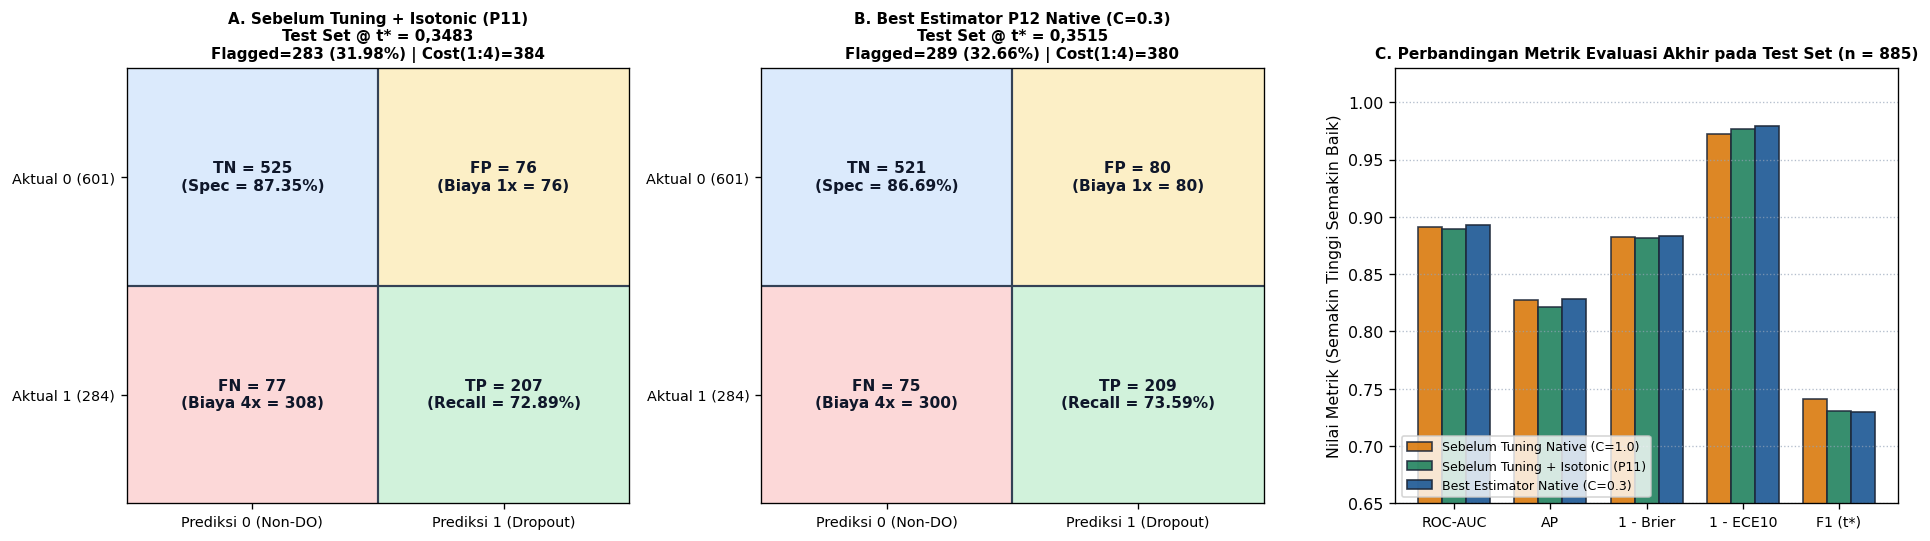

In [27]:
# Bagian G.3 (Visualisasi 3): Grafik Berwarna Confusion Matrix & Perbandingan Metrik Test Set
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6))

pasangan_cm_plot = [
    ("A. Sebelum Tuning + Isotonic (P11)\nTest Set @ t* = 0,3483", cm_test_op_semua["2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"]),
    ("B. Best Estimator P12 Native (C=0.3)\nTest Set @ t* = 0,3515", cm_test_op_semua["3a. Best Estimator P12 — Native (C=0.3, None)"]),
]

# Warna semantik lembut untuk Confusion Matrix: TN (biru muda), FP (kuning lembut), FN (merah muda), TP (hijau lembut)
cm_rgb_bg = np.array([
    [[0.86, 0.92, 0.99], [0.99, 0.94, 0.78]],
    [[0.99, 0.85, 0.85], [0.82, 0.95, 0.86]],
])

for ax_cm, (judul_cm, d_cm) in zip(axes[:2], pasangan_cm_plot):
    ax_cm.imshow(cm_rgb_bg, aspect="auto")
    sel_txt = [
        (0, 0, f"TN = {d_cm['TN']}\n(Spec = {d_cm['Specificity']*100:.2f}%)"),
        (0, 1, f"FP = {d_cm['FP']}\n(Biaya 1x = {d_cm['FP']})"),
        (1, 0, f"FN = {d_cm['FN']}\n(Biaya 4x = {4*d_cm['FN']})"),
        (1, 1, f"TP = {d_cm['TP']}\n(Recall = {d_cm['Recall']*100:.2f}%)"),
    ]
    for r_i, c_i, t_s in sel_txt:
        ax_cm.text(c_i, r_i, t_s, ha="center", va="center", fontsize=9.2, fontweight="bold", color="#0f172a")
    ax_cm.set_xticks([0, 1])
    ax_cm.set_yticks([0, 1])
    ax_cm.set_xticklabels(["Prediksi 0 (Non-DO)", "Prediksi 1 (Dropout)"], fontsize=8.6)
    ax_cm.set_yticklabels([f"Aktual 0 ({n_test_neg})", f"Aktual 1 ({n_test_pos})"], fontsize=8.6)
    ax_cm.axhline(0.5, color="#334155", linewidth=1.3)
    ax_cm.axvline(0.5, color="#334155", linewidth=1.3)
    ax_cm.set_title(f"{judul_cm}\nFlagged={d_cm['Flagged']} ({d_cm['Flagged_Pct']:.2f}%) | Cost(1:4)={d_cm['Error_Cost_1_4']}", fontweight="bold", fontsize=9.1)

ax_m = axes[2]
metrik_lbl = ["ROC-AUC", "AP", "1 - Brier", "1 - ECE10", "F1 (t*)"]
k_p11 = "2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"
k_pre = "2a. Sebelum Tuning — Native (C=1.0, None)"
k_bst = "3a. Best Estimator P12 — Native (C=0.3, None)"

def ambil_vektor_bar(k_m):
    baris_m = df_test_op[df_test_op["Model"] == k_m].iloc[0]
    return [baris_m["Test ROC-AUC"], baris_m["Test AP"], 1.0 - baris_m["Test Brier"], 1.0 - baris_m["Test ECE-10"], baris_m["F1"]]

x_m = np.arange(len(metrik_lbl))
wb = 0.25
ax_m.bar(x_m - wb, ambil_vektor_bar(k_pre), width=wb, color="#d97706", edgecolor="#1e293b", alpha=0.88, label="Sebelum Tuning Native (C=1.0)")
ax_m.bar(x_m, ambil_vektor_bar(k_p11), width=wb, color="#1b7f5a", edgecolor="#1e293b", alpha=0.88, label="Sebelum Tuning + Isotonic (P11)")
ax_m.bar(x_m + wb, ambil_vektor_bar(k_bst), width=wb, color="#1f5a96", edgecolor="#1e293b", alpha=0.92, label="Best Estimator Native (C=0.3)")
ax_m.set_xticks(x_m)
ax_m.set_xticklabels(metrik_lbl, fontsize=8.5)
ax_m.set_ylim(0.65, 1.03)
ax_m.set_ylabel("Nilai Metrik (Semakin Tinggi Semakin Baik)")
ax_m.set_title("C. Perbandingan Metrik Evaluasi Akhir pada Test Set (n = 885)", fontweight="bold", fontsize=9.2)
ax_m.legend(loc="lower left", fontsize=7.5)
ax_m.grid(axis="y", linestyle=":", color="#94a3b8", alpha=0.7)

plt.tight_layout()
plt.savefig(LUARAN_VIS_DIR / "03_evaluasi_akhir_test_p12.png", dpi=300, bbox_inches="tight")
plt.show()


### G.3 Interpretasi Hasil Evaluasi Akhir *Test Set* — Pemisahan Tiga Aspek Evaluasi (Sumber: *Test Set*, $n = 885$)
Agar pembacaan hasil bebas dari klaim berlebihan, evaluasi akhir dipisahkan secara tegas ke dalam tiga aspek berikut:
1. **`Best Estimator` Menurut Kriteria `Mean CV AP` (Kualitas Pemeringkatan Probabilitas):**
   Seluruh varian *Logistic Regression* melampaui *baseline* `DummyClassifier(prior)` (`Test AP = 0,3209`, `Test ROC-AUC = 0,5000`, `Biaya = 1.136`) secara sangat lebar. Di antara kandidat *Logistic Regression*, `Best Estimator Native (C = 0,3, class_weight = None)` mempertahankan keunggulan tipis namun konsisten pada seluruh metrik bebas ambang dan kalibrasi di *Test Set*: **`Test AP = 0,8284`** (`+0,0011` di atas `C = 1,0` *native* `0,8273`; vs. `0,8217` pada `C = 1,0 + Isotonic` P11), **`Test ROC-AUC = 0,8929`** (`+0,0016` di atas `C = 1,0` *native* `0,8913`; vs. `0,8898` pada P11), **`Test Brier Score = 0,1168`**, dan **`Test ECE 10-bin = 0,0209`**.
2. **Konfigurasi dengan Biaya Operasional Terendah dalam Evaluasi (`AP` Tertinggi $\neq$ Biaya Keputusan Minimum):**
    **`Best estimator` berdasarkan `CV AP` bukan merupakan model dengan biaya operasional terendah pada *Test Set*.** Secara faktual di bawah skenario biaya `1:4` dan ambang yang dikunci dari *Validation Set* (`<= 35%`):
   * `Sebelum Tuning — Native (C = 1,0)` pada `t* = 0,3580` mencatat biaya operasional *Test Set* paling rendah, yakni **`364` satuan** (`TP = 212, FP = 76, TN = 525, FN = 72`; `F1 = 0,7413`).
   * `Best Estimator P12 — Native (C = 0,3)` pada `t* = 0,3515` mencatat biaya **`380` satuan** (`TP = 209, FP = 80, TN = 521, FN = 75`; `F1 = 0,7295`).
   * `Sebelum Tuning + Isotonic (Model Final P11: C = 1,0)` pada `t* = 0,3483` mencatat biaya **`384` satuan** (`TP = 207, FP = 76, TN = 525, FN = 77`; `F1 = 0,7302`) — meskipun pada *Validation Set* justru konfigurasi P11 inilah yang memiliki biaya terendah (`342` satuan vs. `345` dan `350`).
   * `Best Estimator + Isotonic (C = 0,3)` pada `t* = 0,3794` mencatat biaya **`402` satuan** (walaupun pada ambang default `0,50` biayanya terendah yakni `438` satuan).
   Temuan ini membuktikan pelajaran metodologis penting: `Average Precision` mengukur ketepatan pengurutan di seluruh rentang kurva PR, sehingga peningkatan tipis `AP` (`+0,0011`) tidak otomatis meminimalkan fungsi biaya diskrit `FP + 4·FN` pada satu titik potong lokal. Meskipun `C = 1,0` *native* menghasilkan biaya uji `364`, keputusan pemilihan model **tidak boleh diubah secara surut berdasarkan hasil *Test Set***.
3. **Batasan & Penjelasan Alternatif:** Selisih `16` satuan biaya antara `C = 0,3` *native* (`380`) dan `C = 1,0` *native* (`364`) berasal dari pergeseran keputusan pada segelintir observasi *borderline* di pita probabilitas sempit `0,34–0,36` pada sampel uji (`284` positif aktual), bukan perbedaan struktural kemampuan diskriminasi model.

---

### G.4 Paragraf Justifikasi Konfigurasi untuk Artikel Ilmiah UAS (Langkah 12)
> Berdasarkan protokol *hyperparameter tuning* terkendali pada Pertemuan 12 yang melanjutkan Pertemuan 11, konfigurasi utama yang direkomendasikan untuk dilaporkan pada artikel ilmiah Proyek UAS adalah **`Pipeline` prapemrosesan 28 fitur konservatif akhir Semester Pertama (`ColumnTransformer` yang memetakan 28 fitur mentah menjadi 213 kolom hasil transformasi pada *Training Set* sebagai array *dense*) dengan pengklasifikasi `LogisticRegression(C = 0,3, class_weight = None, l1_ratio = 0.0, solver = 'lbfgs', max_iter = 2000)` serta ambang operasional `t* = 0,3515` yang dikunci dari *Validation Set* (skenario biaya relatif `1:4` dan batas kapasitas simulasi `35%`)**, disertai pelaporan berdampingan konfigurasi pra-*tuning* `C = 1,0` (*native* `t* = 0,3580` dan *Isotonic* P11 `t* = 0,3483`) sebagai analisis pembanding yang transparan. Pemilihan `C = 0,3` dan `class_weight = None` dipertahankan secara disiplin mengikuti aturan pra-komitmen validasi silang (`Mean CV AP` tertinggi `0,8131 ± 0,0136`, `Mean CV ROC-AUC = 0,8756 ± 0,0137`) serta terbukti konsisten meraih peringkat dan kalibrasi *native* terbaik pada *Test Set* (`Test AP = 0,8284`, `Test ROC-AUC = 0,8929`, `Test Brier = 0,1168`, `Test ECE = 0,0209`; norma koefisien menyusut `32,0%` dari `6,4629` menjadi `4,3923` sebagai konsekuensi regularisasi $L_2$). Pada saat yang sama, naskah artikel wajib menyatakan secara jujur bahwa kenaikan `AP` terhadap `C = 1,0` sangat kecil (`+0,0017` di CV; `+0,0011` di *Test Set*) dan bahwa skor `AP` tertinggi tidak identik dengan biaya keputusan operasional terendah (`Test Cost` `C = 0,3` *native* sebesar `380` satuan berbanding `384` satuan pada P11 `C = 1,0 + Isotonic` dan `364` satuan pada `C = 1,0` *native*), sehingga kontribusi ilmiah artikel bertumpu pada ketatnya metodologi evaluasi bebas kebocoran, bukan klaim peningkatan akurasi yang dramatis.


---
## BAGIAN H — ANALISIS KESALAHAN, LOG EKSPERIMEN, LATIHAN ANALITIS, KESIMPULAN, DAN INTEGRITAS AKADEMIK

### H.1 Analisis Kesalahan pada *Validation Set* (Minimal Tiga Kasus Penting — Modul Seksi 13)
Sesuai aturan perlindungan *Test Set*, bedah kasus kesalahan dilakukan sepenuhnya pada ***Validation Set* (`n = 885`)** untuk membandingkan perilaku model sebelum tuning (`C = 1,0`) dan sesudah tuning (`C = 0,3`). Pembahasan memisahkan secara tegas **fakta nilai fitur**, **interpretasi perilaku model**, dan **hipotesis yang belum dapat dibuktikan dari data**.


In [28]:
# Bagian H.1 (Kode): Ekstraksi Empat Kasus/Segmen Kesalahan Penting pada Validation Set
kamus_prodi = {
    33: "Biofuel Production Tech.", 171: "Animation & Multimedia Design", 8014: "Social Service (Evening)",
    9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing", 9119: "Informatics Engineering",
    9130: "Equinculture", 9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
    9556: "Oral Hygiene", 9670: "Advertising & Marketing Mgmt", 9773: "Journalism & Communication",
    9853: "Basic Education", 9991: "Management (Evening)",
}

df_err_val = df_val.copy()
df_err_val["prodi"] = df_err_val["Course"].map(kamus_prodi).fillna("Other")
df_err_val["prob_pre_nat"] = proba_val_semua["2a. Sebelum Tuning — Native (C=1.0, None)"].round(4)
df_err_val["prob_best_nat"] = proba_val_semua["3a. Best Estimator P12 — Native (C=0.3, None)"].round(4)
df_err_val["prob_p11_iso"] = proba_val_semua["2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"].round(4)
df_err_val["pred_pre_op"] = (df_err_val["prob_pre_nat"] >= threshold_terkunci_val["2a. Sebelum Tuning — Native (C=1.0, None)"]).astype(int)
df_err_val["pred_best_op"] = (df_err_val["prob_best_nat"] >= threshold_terkunci_val["3a. Best Estimator P12 — Native (C=0.3, None)"]).astype(int)

kasus_ids_p12 = ["OBS_4422", "OBS_2705", "OBS_2707", "OBS_2465"]
df_detail_kasus = df_err_val[df_err_val["obs_id"].isin(kasus_ids_p12)].set_index("obs_id").loc[kasus_ids_p12].reset_index()
kol_tampil_err = [
    "obs_id", "Target", "label_dropout", "prodi", "Age at enrollment", "Scholarship holder",
    "Admission grade", "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
    "prob_pre_nat", "prob_best_nat", "prob_p11_iso", "pred_pre_op", "pred_best_op",
]
print("=== FAKTA DATA EMPAT KASUS ANALISIS KESALAHAN PADA VALIDATION SET ===")
display(df_detail_kasus[kol_tampil_err])

analisis_kesalahan = pd.DataFrame([
    {
        "contoh_atau_segmen": "Kasus 1 — False Negative Persisten Lintas Tuning (OBS_4422; Aktual: Dropout)",
        "bukti": (
            "Fakta: Prodi Nursing, usia 30, penerima beasiswa, Admission grade 149,5; lulus 7/7 MK Sem 1 "
            "(nilai 14,91). Skor tetap sangat rendah sebelum tuning (0,0401) maupun sesudah tuning C=0,3 (0,0410)."
        ),
        "kemungkinan_penyebab": (
            "Interpretasi: Seluruh bukti akademik Sem 1 sangat unggul sehingga model linier memberi log-odds negatif kuat. "
            "Hipotesis belum terbukti: perubahan kondisi non-akademik atau kejadian setelah Sem 1 yang tidak terekam."
        ),
        "kategori_masalah": "Keterbatasan observabilitas data (fitur terbatas s.d. akhir Semester 1)",
        "usulan_uji": "Menguji pemodelan bertahap per semester (phased prediction) bila data pemantauan Semester 2 tersedia.",
    },
    {
        "contoh_atau_segmen": "Kasus 2 — False Positive Persisten Subkelas Enrolled (OBS_2705; Aktual: Enrolled -> Kelas 0)",
        "bukti": (
            "Fakta: Prodi Advertising & Marketing, usia 19, tanpa beasiswa; mengambil 5 MK, 10 evaluasi ujian, "
            "tetapi lulus 0/5 MK (nilai 0,0). Skor sangat tinggi pada C=1,0 (0,9449) dan tetap 0,9364 pada C=0,3."
        ),
        "kemungkinan_penyebab": (
            "Interpretasi: Kegagalan penuh 0/5 MK identik dengan profil mayoritas mahasiswa Dropout. "
            "Status Enrolled mengalami sensor kanan (right-censoring): belum diketahui apakah kelak lulus atau putus studi."
        ),
        "kategori_masalah": "Definisi target & evaluasi (right-censoring pada subkelas Enrolled di kelas negatif)",
        "usulan_uji": "Memisahkan pelaporan metrik subkelompok Enrolled atau menerapkan analisis kesintasan (survival analysis).",
    },
    {
        "contoh_atau_segmen": "Kasus 3 — Borderline FP yang Terkoreksi oleh Regularisasi C=0,3 (OBS_2707; Aktual: Graduate)",
        "bukti": (
            "Fakta: Prodi Equinculture, usia 20, lulus 4/5 MK Sem 1 (nilai 11,75). Pada C=1,0 skor 0,3738 >= t*=0,3580 "
            "(tercatat FP), sedangkan pada C=0,3 skor menyusut ke 0,3477 < t*=0,3515 (berubah benar menjadi TN)."
        ),
        "kemungkinan_penyebab": (
            "Interpretasi: Pada C=1,0 bobot positif indikator kategori prodi/okupasi mendorong peluang melewati ambang; "
            "penyusutan L2 pada C=0,3 menahan kontribusi fitur kategorikal sehingga keputusan berbalik akurat."
        ),
        "kategori_masalah": "interaksi representasi One-Hot Encoding, regularisasi model, dan threshold operasional",
        "usulan_uji": "Menguji pengelompokan kategori jarang (min_frequency pada OneHotEncoder) bersama regularisasi ElasticNet.",
    },
    {
        "contoh_atau_segmen": "Kasus 4 — Borderline FN Akibat Penyusutan Skor di Perbatasan Ambang (OBS_2465; Aktual: Dropout)",
        "bukti": (
            "Fakta: Prodi Management (Evening), usia 29, lulus 4/5 MK Sem 1 (nilai 11,25). Skor turun tipis dari "
            "0,3541 (C=1,0) menjadi 0,3413 (C=0,3), tepat di bawah ambang t*=0,3515 sehingga terlewat sebagai FN."
        ),
        "kemungkinan_penyebab": (
            "Interpretasi: Mahasiswa kelas malam dengan capaian Sem 1 cukup baik (4/5 lulus) berada di zona abu-abu "
            "probabilitas ~0,34–0,36; regularisasi lebih kuat sedikit menurunkan skor di bawah batas kapasitas 35%."
        ),
        "kategori_masalah": "Keterbatasan model linier aditif & kendala batas kuota threshold",
        "usulan_uji": "Menambahkan fitur rekayasa rasio kelulusan (approved/enrolled) dan interaksi kelas malam × usia.",
    },
])
analisis_kesalahan.to_csv(LUARAN_TAB_DIR / "09_analisis_kesalahan_validasi_p12.csv", index=False)
print("\n=== TABEL ANALISIS KESALAHAN (SUMBER: VALIDATION SET, n = 885) ===")
display(analisis_kesalahan)


=== FAKTA DATA EMPAT KASUS ANALISIS KESALAHAN PADA VALIDATION SET ===


,obs_id,Target,label_dropout,prodi,Age at enrollment,Scholarship holder,Admission grade,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),prob_pre_nat,prob_best_nat,prob_p11_iso,pred_pre_op,pred_best_op
0,OBS_4422,Dropout,1,Nursing,30,1,149.5000,7,8,7,14.9125,0.0401,0.0410,0.0482,0,0
1,OBS_2705,Enrolled,0,Advertising & Marketing Mgmt,19,0,108.0000,5,10,0,0.0000,0.9449,0.9364,0.9867,1,1
2,OBS_2707,Graduate,0,Equinculture,20,0,132.4000,5,7,4,11.7500,0.3738,0.3477,0.3747,1,0
3,OBS_2465,Dropout,1,Management (Evening),29,0,141.4000,5,7,4,11.2500,0.3541,0.3413,0.3582,0,0



=== TABEL ANALISIS KESALAHAN (SUMBER: VALIDATION SET, n = 885) ===


,contoh_atau_segmen,bukti,kemungkinan_penyebab,kategori_masalah,usulan_uji
0,Kasus 1 — False Negative Persisten Lintas Tuning (OBS_4422; Aktual: Dropout),"Fakta: Prodi Nursing, usia 30, penerima beasiswa, Admission grade 149,5; lulus 7/7 MK Sem 1 (nilai 14,91). Skor teta...",Interpretasi: Seluruh bukti akademik Sem 1 sangat unggul sehingga model linier memberi log-odds negatif kuat. Hipote...,Keterbatasan observabilitas data (fitur terbatas s.d. akhir Semester 1),Menguji pemodelan bertahap per semester (phased prediction) bila data pemantauan Semester 2 tersedia.
1,Kasus 2 — False Positive Persisten Subkelas Enrolled (OBS_2705; Aktual: Enrolled -> Kelas 0),"Fakta: Prodi Advertising & Marketing, usia 19, tanpa beasiswa; mengambil 5 MK, 10 evaluasi ujian, tetapi lulus 0/5 M...",Interpretasi: Kegagalan penuh 0/5 MK identik dengan profil mayoritas mahasiswa Dropout. Status Enrolled mengalami se...,Definisi target & evaluasi (right-censoring pada subkelas Enrolled di kelas negatif),Memisahkan pelaporan metrik subkelompok Enrolled atau menerapkan analisis kesintasan (survival analysis).
2,"Kasus 3 — Borderline FP yang Terkoreksi oleh Regularisasi C=0,3 (OBS_2707; Aktual: Graduate)","Fakta: Prodi Equinculture, usia 20, lulus 4/5 MK Sem 1 (nilai 11,75). Pada C=1,0 skor 0,3738 >= t*=0,3580 (tercatat ...","Interpretasi: Pada C=1,0 bobot positif indikator kategori prodi/okupasi mendorong peluang melewati ambang; penyusuta...","interaksi representasi One-Hot Encoding, regularisasi model, dan threshold operasional",Menguji pengelompokan kategori jarang (min_frequency pada OneHotEncoder) bersama regularisasi ElasticNet.
3,Kasus 4 — Borderline FN Akibat Penyusutan Skor di Perbatasan Ambang (OBS_2465; Aktual: Dropout),"Fakta: Prodi Management (Evening), usia 29, lulus 4/5 MK Sem 1 (nilai 11,25). Skor turun tipis dari 0,3541 (C=1,0) m...",Interpretasi: Mahasiswa kelas malam dengan capaian Sem 1 cukup baik (4/5 lulus) berada di zona abu-abu probabilitas ...,Keterbatasan model linier aditif & kendala batas kuota threshold,Menambahkan fitur rekayasa rasio kelulusan (approved/enrolled) dan interaksi kelas malam × usia.


In [29]:
# Bagian H.2 (Kode): Tabel Log Eksperimen Tuning Sesuai Struktur Modul Resmi Seksi 11
baris_terburuk_cv = cv_urut.iloc[-1]
baris_c003_none = cv_urut[(cv_urut["param_clf__C"] == 0.03) & (cv_urut["class_weight_str"] == "None")].iloc[0]
rasio_fit_terburuk_vs_best = float(baris_terburuk_cv["mean_fit_time"]) / float(cv_urut.iloc[0]["mean_fit_time"])

log_tuning = pd.DataFrame([
    {
        "eksperimen": "E1 — Baseline DummyClassifier (prior)",
        "ruang_cari": "Tidak ada (strategy='prior')",
        "jumlah_kandidat": 1,
        "cv": "5-Fold StratifiedKFold (Train, n=2.654)",
        "skor_terbaik": f"CV AP = {np.mean(cv_res_dummy['test_AP']):.4f} ± {np.std(cv_res_dummy['test_AP'], ddof=0):.4f}",
        "waktu": f"{durasi_dummy:.4f} s (6 fit)",
        "keputusan": "Disimpan sebagai batas bawah no-skill (pembanding wajib).",
    },
    {
        "eksperimen": "E2 — Logistic Regression Sebelum Tuning (Konfigurasi P11)",
        "ruang_cari": "Titik tunggal: C=1.0, class_weight=None, l1_ratio=0.0",
        "jumlah_kandidat": 1,
        "cv": "5-Fold StratifiedKFold (Train, n=2.654)",
        "skor_terbaik": f"CV AP = {np.mean(cv_res_sebelum['test_AP']):.4f} ± {np.std(cv_res_sebelum['test_AP'], ddof=0):.4f}",
        "waktu": f"{durasi_sebelum:.4f} s (6 fit)",
        "keputusan": "Acuan pra-tuning; celah Train-CV AP +0,0416 mendorong uji regularisasi.",
    },
    {
        "eksperimen": "E3 — GridSearchCV Terkendali (Seluruh 12 Kandidat)",
        "ruang_cari": "clf__C: [0.03, 0.1, 0.3, 1.0, 3.0, 10.0] × clf__class_weight: [None, 'balanced']",
        "jumlah_kandidat": 12,
        "cv": "5-Fold StratifiedKFold (60 CV fit + 1 refit = 61 fit)",
        "skor_terbaik": f"CV AP = {best_score_cv_ap:.4f} ± {float(cv_urut.iloc[0]['std_test_AP']):.4f} (C=0.3, None)",
        "waktu": f"{wall_clock_detik:.4f} s wall-clock (refit {refit_time_s:.4f} s)",
        "keputusan": "Ditemukan C=0.3 & class_weight=None sebagai best estimator menurut Mean CV AP (+0,0017 sangat tipis atas C=1.0).",
    },
    {
        "eksperimen": "E3a — Catatan Kandidat Terburuk Grid (Overfitting C=10.0, 'balanced')",
        "ruang_cari": "Sub-hasil GridSearchCV: C=10.0, class_weight='balanced'",
        "jumlah_kandidat": 1,
        "cv": "5-Fold StratifiedKFold (bagian dari 60 CV fit)",
        "skor_terbaik": f"CV AP = {float(baris_terburuk_cv['mean_test_AP']):.4f} ± {float(baris_terburuk_cv['std_test_AP']):.4f} (Train AP={float(baris_terburuk_cv['mean_train_AP']):.4f})",
        "waktu": f"Mean fit = {float(baris_terburuk_cv['mean_fit_time']):.4f} s/fold",
        "keputusan": f"Ditolak; regularisasi terlalu lemah memicu overfitting (+0,0612 gap) & waktu fit ~{rasio_fit_terburuk_vs_best:.2f}x kandidat terbaik.",
    },
    {
        "eksperimen": "E3b — Catatan Kandidat Underfitting Grid (C=0.03, None)",
        "ruang_cari": "Sub-hasil GridSearchCV: C=0.03, class_weight=None",
        "jumlah_kandidat": 1,
        "cv": "5-Fold StratifiedKFold (bagian dari 60 CV fit)",
        "skor_terbaik": f"CV AP = {float(baris_c003_none['mean_test_AP']):.4f} ± {float(baris_c003_none['std_test_AP']):.4f} (Train AP={float(baris_c003_none['mean_train_AP']):.4f})",
        "waktu": f"Mean fit = {float(baris_c003_none['mean_fit_time']):.4f} s/fold",
        "keputusan": "Ditolak; penalti L2 terlalu besar menahan sinyal fitur (underfitting).",
    },
    {
        "eksperimen": "E4 — Evaluasi Kalibrasi Isotonic CV=5 pada Best Estimator (C=0.3)",
        "ruang_cari": "CalibratedClassifierCV(method='isotonic', cv=5) di atas best_estimator_",
        "jumlah_kandidat": 1,
        "cv": "5-Fold Internal Calibration di Train + Evaluasi Val (n=885)",
        "skor_terbaik": f"Val AP = {average_precision_score(y_val, proba_val_semua['3b. Best Estimator P12 + Isotonic CV=5 (C=0.3)']):.4f}, Brier = {brier_score_loss(y_val, proba_val_semua['3b. Best Estimator P12 + Isotonic CV=5 (C=0.3)']):.4f}",
        "waktu": f"{durasi_iso_best:.4f} s (5 fit tambahan)",
        "keputusan": "Tidak dipilih sebagai model utama P12 karena Best Estimator Native sudah lebih baik di Val (AP=0,8396, Brier=0,1140, Cost=345 vs 352); tetap dilaporkan sebagai pembanding.",
    },
])
log_tuning.to_csv(LUARAN_TAB_DIR / "10_log_eksperimen_tuning_p12.csv", index=False)
print("=== TABEL LOG EKSPERIMEN TUNING (MODUL SEKSI 11) ===")
display(log_tuning)


=== TABEL LOG EKSPERIMEN TUNING (MODUL SEKSI 11) ===


,eksperimen,ruang_cari,jumlah_kandidat,cv,skor_terbaik,waktu,keputusan
0,E1 — Baseline DummyClassifier (prior),Tidak ada (strategy='prior'),1,"5-Fold StratifiedKFold (Train, n=2.654)",CV AP = 0.3214 ± 0.0008,0.3472 s (6 fit),Disimpan sebagai batas bawah no-skill (pembanding wajib).
1,E2 — Logistic Regression Sebelum Tuning (Konfigurasi P11),"Titik tunggal: C=1.0, class_weight=None, l1_ratio=0.0",1,"5-Fold StratifiedKFold (Train, n=2.654)",CV AP = 0.8114 ± 0.0137,0.5645 s (6 fit),"Acuan pra-tuning; celah Train-CV AP +0,0416 mendorong uji regularisasi."
2,E3 — GridSearchCV Terkendali (Seluruh 12 Kandidat),"clf__C: [0.03, 0.1, 0.3, 1.0, 3.0, 10.0] × clf__class_weight: [None, 'balanced']",12,5-Fold StratifiedKFold (60 CV fit + 1 refit = 61 fit),"CV AP = 0.8131 ± 0.0136 (C=0.3, None)",2.6596 s wall-clock (refit 0.0655 s),"Ditemukan C=0.3 & class_weight=None sebagai best estimator menurut Mean CV AP (+0,0017 sangat tipis atas C=1.0)."
3,"E3a — Catatan Kandidat Terburuk Grid (Overfitting C=10.0, 'balanced')","Sub-hasil GridSearchCV: C=10.0, class_weight='balanced'",1,5-Fold StratifiedKFold (bagian dari 60 CV fit),CV AP = 0.7954 ± 0.0201 (Train AP=0.8566),Mean fit = 0.1367 s/fold,"Ditolak; regularisasi terlalu lemah memicu overfitting (+0,0612 gap) & waktu fit ~1.46x kandidat terbaik."
4,"E3b — Catatan Kandidat Underfitting Grid (C=0.03, None)","Sub-hasil GridSearchCV: C=0.03, class_weight=None",1,5-Fold StratifiedKFold (bagian dari 60 CV fit),CV AP = 0.8018 ± 0.0134 (Train AP=0.8201),Mean fit = 0.1090 s/fold,Ditolak; penalti L2 terlalu besar menahan sinyal fitur (underfitting).
5,E4 — Evaluasi Kalibrasi Isotonic CV=5 pada Best Estimator (C=0.3),"CalibratedClassifierCV(method='isotonic', cv=5) di atas best_estimator_",1,5-Fold Internal Calibration di Train + Evaluasi Val (n=885),"Val AP = 0.8364, Brier = 0.1148",0.3546 s (5 fit tambahan),"Tidak dipilih sebagai model utama P12 karena Best Estimator Native sudah lebih baik di Val (AP=0,8396, Brier=0,1140,..."


---
### H.3 Jawaban Lima Latihan Analitis

1. **Berapa jumlah `fit` untuk 12 kandidat dan 5 fold?**
   Evaluasi validasi silang membutuhkan $12 \text{ kandidat} \times 5 \text{ fold} = \mathbf{60}$ **proses `fit`**. Apabila parameter `refit=True` (atau `refit="AP"` seperti pada eksperimen ini) diaktifkan pada `GridSearchCV`, terdapat **$\mathbf{1}$ proses `fit` tambahan** untuk melatih ulang konfigurasi terbaik pada keseluruhan *Training Set*, sehingga total proses pelatihan di dalam `GridSearchCV` adalah **$60 + 1 = \mathbf{61}$ `fit`**.

2. **Mengapa pemilihan model berdasarkan *test score* menyebabkan hasil yang terlalu optimistis?**
   Jika peneliti membandingkan banyak konfigurasi dan memilih model terbaik berdasarkan skor pada *Test Set*, maka fluktuasi kebetulan (*sampling noise*) yang menguntungkan suatu kandidat pada sampel uji ikut terpilih dalam keputusan. Akibatnya, *Test Set* bocor menjadi bagian dari proses optimasi (*selection bias* / *multiple-testing leakage*), kehilangan independensinya sebagai penguji data baru, dan skor yang dilaporkan menjadi bias terlalu tinggi dibandingkan kinerja sesungguhnya di populasi luar.

3. **Kapan `RandomizedSearchCV` lebih efisien daripada `GridSearchCV`?**
   `RandomizedSearchCV` lebih efisien ketika ruang pencarian berukuran sangat besar atau berdimensi tinggi (banyak *hyperparameter* diuji sekaligus), memiliki *hyperparameter* bernilai kontinu yang sensitif sementara sebagian *hyperparameter* lain pengaruhnya kecil (*low effective dimensionality*), atau ketika model mahal dilatih sehingga anggaran komputasi membatasi jumlah evaluasi jauh di bawah total kombinasi grid penuh.

4. **Apa arti `best_params_`?**
   `best_params_` adalah atribut berbentuk *dictionary* Python pada objek hasil pencarian (`GridSearchCV` / `RandomizedSearchCV`) yang menyimpan kombinasi nilai *hyperparameter* peraih rata-rata skor validasi silang tertinggi berdasarkan metrik evaluasi yang ditentukan pada argumen `refit` (dalam eksperimen ini `{'clf__C': 0.3, 'clf__class_weight': None}` berdasarkan `Average Precision`).

5. **Mengapa hasil terbaik tetap harus dibandingkan dengan *baseline*?**
   Angka metrik tunggal seperti `AP` atau `ROC-AUC` tidak bermakna tanpa konteks prevalensi dan tingkat kesulitan data. Pembandingan terhadap *baseline* sederhana (`DummyClassifier`) membuktikan secara objektif apakah model hasil *tuning* benar-benar mempelajari pola prediktif yang melampaui tebakan tanpa fitur, sedangkan pembandingan terhadap model standar sebelum *tuning* membuktikan apakah tambahan waktu dan kompleksitas *tuning* sungguh sepadan dengan kenaikan kinerjanya.

---

### H.4 Kesimpulan (250–400 Kata — Modul Seksi 14 & Master Prompt Bagian 27)

Eksperimen *hyperparameter tuning* terkendali menggunakan `GridSearchCV` 5-fold berstrata pada *Training Set* (`n = 2.654`) untuk `Pipeline` 28 fitur konservatif akhir Semester Pertama memilih konfigurasi terbaik `best_params_ = {'clf__C': 0.3, 'clf__class_weight': None}` dengan `best_score_` (`Mean CV AP`) sebesar `0,8131 ± 0,0136` dan `Mean CV ROC-AUC` sebesar `0,8756 ± 0,0137`. Dibandingkan *baseline* `DummyClassifier(strategy="prior")` yang tidak mempelajari pola fitur (`Mean CV AP = 0,3214 ± 0,0008`; `Test AP = 0,3209`; `Test ROC-AUC = 0,5000`), konfigurasi hasil *tuning* memberikan peningkatan kinerja yang sangat besar baik pada validasi silang (`+0,4917` poin `AP`), *Validation Set* (`Val AP = 0,8396` lawan `0,3209`), maupun *Test Set* (`Test AP = 0,8284`; `Test ROC-AUC = 0,8929`).

Namun, dibandingkan model *Logistic Regression* konfigurasi Pertemuan 11 sebelum *tuning* (`C = 1,0`, `class_weight = None`), peningkatan skor sangat kecil dan tidak diklaim signifikan secara statistik: `Mean CV AP` hanya naik `+0,0017` (`0,8114` ke `0,8131`), `Mean CV ROC-AUC` naik `+0,0024` (`0,8732` ke `0,8756`), `Test AP` naik `+0,0011` (`0,8273` ke `0,8284`), dan `Test ROC-AUC` naik `+0,0016` (`0,8913` ke `0,8929`). Simpangan baku populasi antar-lipatan CV (`ddof=0`, sekitar `0,0136`) stabil pada `C <= 1,0`, tetapi membesar hingga `0,0205` pada `C = 10,0` akibat *overfitting* pada `213` kolom hasil transformasi (dari `28` fitur mentah). Norma koefisien menyusut `32,0%` (`6,4629` menjadi `4,3923`) sebagai konsekuensi matematis regularisasi, disertai perbaikan kalibrasi *native* (`Val ECE` turun dari `0,0444` ke `0,0346`; `Test Brier = 0,1168`, `Test ECE = 0,0209`). Walau unggul tipis pada `AP`, model ber-`AP` tertinggi bukan peraih biaya operasional terendah: pada *Test Set*, biaya `C = 0,3` *native* (`380` satuan pada `t* = 0,3515`) lebih rendah dari P11 `C = 1,0 + Isotonic` (`384` satuan), namun lebih tinggi dibanding `C = 1,0` *native* (`364` satuan).

Dari sisi efisiensi, 61 proses `fit` selesai dalam waktu singkat pada perangkat lokal sehingga *tuning* layak dilakukan untuk mengaudit batas regularisasi, namun tidak layak diperluas ke grid raksasa tanpa fitur baru. Keterbatasan utama studi ini meliputi asal data dari satu institusi di Portugal, sensor kanan subkelas `Enrolled`, ketiadaan informasi pasca-Semester Pertama pada kasus *False Negative* persisten, sifat simulasi pada rasio biaya `1:4` dan kuota `35%`, serta fakta bahwa *Test Set* berasal dari partisi yang pernah dilaporkan pada evaluasi akhir P11. Eksperimen lanjutan yang relevan mencakup rekayasa rasio kelulusan kurikuler, pengujian regularisasi `ElasticNet`, serta pemodelan kesintasan untuk menangani observasi `Enrolled`.

---

### H.5 Ringkasan Keterbatasan Eksperimen
1. **Validitas Eksternal & Geografis:** Dataset berasal dari satu politeknik negeri di Portugal (2008/2009–2018/2019), sehingga model dan *threshold* tidak otomatis berlaku pada perguruan tinggi di Indonesia tanpa pelatihan serta validasi ulang lokal.
2. **Sensor Kanan (*Right-Censoring*) Kelas `Enrolled`:** Sebanyak `794` mahasiswa (`17,95%`) belum memiliki status akhir lulus/putus studi saat pencatatan ditutup, yang berkontribusi besar terhadap *False Positive* berprobabilitas tinggi.
3. **Batas Informasi Akhir Semester Pertama:** Mahasiswa yang berprestasi baik pada Semester Pertama tetapi mengalami kendala pada semester berikutnya tidak dapat terdeteksi oleh spesifikasi 28 fitur maupun oleh penyetelan *hyperparameter*.
4. **Status Riwayat *Test Set* Lintas Pertemuan:** Meskipun *Test Set* sepenuhnya dilindungi dari proses `GridSearchCV`, kalibrasi, dan pemilihan *threshold* di Pertemuan 12, partisi uji yang sama pernah dievaluasi satu kali pada tahap akhir Pertemuan 11 demi konsistensi perbandingan antartugas.
5. **Asumsi Simulasi Biaya & Kapasitas:** Matriks biaya `1:4` dan kuota `35%` merupakan skenario analitis pendukung keputusan, bukan biaya finansial atau kapasitas konselor aktual.

---

### H.6 Integritas Akademik, Sumber Data, dan Pernyataan Penggunaan AI (Modul Seksi 15)
* **Sumber Resmi & Lisensi Dataset:** Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository (ID #697). https://doi.org/10.24432/C5MC89 — Lisensi terbuka **Creative Commons Attribution 4.0 International (`CC BY 4.0`)**, bebas dari informasi identitas pribadi (*anonymized*).
* **Reproduksibilitas Perangkat Lunak:** `SEED = 42`; spesifikasi lengkap versi `Python`, `NumPy`, `Pandas`, `Scikit-learn`, `Matplotlib`, dan `Seaborn` tercatat otomatis pada Tabel Bagian C.1.
* **Pernyataan Jujur Penggunaan AI Generatif:**
  > *Antigravity digunakan sebagai alat bantu dalam penyusunan struktur kode modular, pemeriksaan pencegahan data leakage pada Pipeline dan GridSearchCV, serta penyusunan draf awal dokumentasi teknis. Seluruh logika eksperimen, pemilihan ruang pencarian, eksekusi kode, angka hasil validasi silang maupun data uji, sitasi referensi, dan ketepatan interpretasi diperiksa serta diverifikasi kembali secara menyeluruh oleh penulis (Fadli Hifziansyah — 241730042). Penulis memahami setiap bagian kode dan bertanggung jawab penuh atas keaslian serta validitas akademik isi notebook ini.*

---

### H.7 Daftar Pustaka
1. Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
2. Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.
3. Davis, J., & Goadrich, M. (2006). The relationship between Precision-Recall and ROC curves. *Proceedings of the 23rd International Conference on Machine Learning (ICML '06)*, 233–240. https://doi.org/10.1145/1143844.1143874
4. Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI '01)*, 973–978.
5. Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). John Wiley & Sons. https://doi.org/10.1002/9781118548387
6. Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning (ICML '05)*, 625–632. https://doi.org/10.1145/1102351.1102430
7. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
8. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
9. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
10. Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432


In [30]:
# Bagian H.8 (Kode): Audit Otomatis Konsistensi Metodologi (Pemisahan Assertion Dinamis vs. Regresi Spesifik)
teks_kesimpulan_h4 = (
    "Eksperimen hyperparameter tuning terkendali menggunakan GridSearchCV 5-fold berstrata pada Training Set (n = 2.654) "
    "untuk Pipeline 28 fitur konservatif akhir Semester Pertama memilih konfigurasi terbaik best_params_ = {'clf__C': 0.3, 'clf__class_weight': None} "
    "dengan best_score_ (Mean CV AP) sebesar 0,8131 ± 0,0136 dan Mean CV ROC-AUC sebesar 0,8756 ± 0,0137. Dibandingkan baseline "
    "DummyClassifier(strategy=\"prior\") yang tidak mempelajari pola fitur (Mean CV AP = 0,3214 ± 0,0008; Test AP = 0,3209; Test ROC-AUC = 0,5000), "
    "konfigurasi hasil tuning memberikan peningkatan kinerja yang sangat besar baik pada validasi silang (+0,4917 poin AP), Validation Set "
    "(Val AP = 0,8396 lawan 0,3209), maupun Test Set (Test AP = 0,8284; Test ROC-AUC = 0,8929). "
    "Namun, dibandingkan model Logistic Regression konfigurasi Pertemuan 11 sebelum tuning (C = 1,0, class_weight = None), peningkatan skor "
    "sangat kecil dan tidak diklaim signifikan secara statistik: Mean CV AP hanya naik +0,0017 (0,8114 ke 0,8131), Mean CV ROC-AUC naik +0,0024 "
    "(0,8732 ke 0,8756), Test AP naik +0,0011 (0,8273 ke 0,8284), dan Test ROC-AUC naik +0,0016 (0,8913 ke 0,8929). Simpangan baku populasi "
    "antar-lipatan CV (ddof=0, sekitar 0,0136) stabil pada C <= 1,0, tetapi membesar hingga 0,0205 pada C = 10,0 akibat overfitting pada 213 "
    "kolom hasil transformasi (dari 28 fitur mentah). Norma koefisien menyusut 32,0% (6,4629 menjadi 4,3923) sebagai konsekuensi matematis "
    "regularisasi, disertai perbaikan kalibrasi native (Val ECE turun dari 0,0444 ke 0,0346; Test Brier = 0,1168, Test ECE = 0,0209). Walau "
    "unggul tipis pada AP, model ber-AP tertinggi bukan peraih biaya operasional terendah: pada Test Set, biaya C = 0,3 native (380 satuan pada "
    "t* = 0,3515) lebih rendah dari P11 C = 1,0 + Isotonic (384 satuan), namun lebih tinggi dibanding C = 1,0 native (364 satuan). "
    "Dari sisi efisiensi, 61 proses fit selesai dalam waktu singkat pada perangkat lokal sehingga tuning layak dilakukan untuk mengaudit batas "
    "regularisasi, namun tidak layak diperluas ke grid raksasa tanpa fitur baru. Keterbatasan utama studi ini meliputi asal data dari satu institusi "
    "di Portugal, sensor kanan subkelas Enrolled, ketiadaan informasi pasca-Semester Pertama pada kasus False Negative persisten, sifat simulasi "
    "pada rasio biaya 1:4 dan kuota 35%, serta fakta bahwa Test Set berasal dari partisi yang pernah dilaporkan pada evaluasi akhir P11. Eksperimen "
    "lanjutan yang relevan mencakup rekayasa rasio kelulusan kurikuler, pengujian regularisasi ElasticNet, serta pemodelan kesintasan untuk menangani observasi Enrolled."
)
jumlah_kata_kesimpulan = len(teks_kesimpulan_h4.split())

# ------------------------------------------------------------------------------
# A. PEMERIKSAAN INVARIAN METODOLOGIS & RUMUS DINAMIS (BERLAKU UMUM)
# ------------------------------------------------------------------------------
assert len(df_train) + len(df_val) + len(df_test_final) == len(df_uci)
assert set(idx_dev).isdisjoint(set(idx_test_locked)), "Kebocoran indeks antara data pengembangan dan Test Set!"
assert isinstance(search.estimator, Pipeline) and "prep" in search.estimator.named_steps, "Preprocessing wajib berada di dalam Pipeline!"
assert len(cv_results_df) == 12 and cv_5fold.get_n_splits() == 5 and n_total_gs_fits == 61
assert search.refit == "AP"
assert wall_clock_detik > 0.0 and refit_time_s > 0.0
assert list(df_top5["Rank"]) == [1, 2, 3, 4, 5]
assert len(analisis_kesalahan) >= 3 and len(log_tuning) >= 5
assert 250 <= jumlah_kata_kesimpulan <= 400, f"Panjang kesimpulan {jumlah_kata_kesimpulan} kata di luar rentang 250-400!"

for nama_m, d_cm in cm_test_op_semua.items():
    tp, fp, tn, fn = d_cm["TP"], d_cm["FP"], d_cm["TN"], d_cm["FN"]
    assert tp + fp + tn + fn == len(y_test_final)
    assert d_cm["Error_Cost_1_4"] == 1 * fp + 4 * fn

print(f"1. Pemeriksaan invarian metodologis & rumus dinamis LULUS (Panjang kesimpulan H.4 = {jumlah_kata_kesimpulan} kata [rentang wajib 250-400]).")

# ------------------------------------------------------------------------------
# B. PEMERIKSAAN REGRESI SPESIFIK EKSPERIMEN (KHUSUS DATASET UCI #697 & SEED=42)
# ------------------------------------------------------------------------------
assert clf_terbaik.l1_ratio == 0.0 and clf_sebelum.l1_ratio == 0.0
assert clf_terbaik.coef_.shape == (1, 213) and n_fitur_trans == 213
assert round(norm_l2_sebelum, 4) == 6.4629 and round(norm_l2_terbaik, 4) == 4.3923
assert round((1.0 - norm_l2_terbaik / norm_l2_sebelum) * 100.0, 1) == 32.0
assert best_params_terpilih == {"clf__C": 0.3, "clf__class_weight": None}
assert round(best_score_cv_ap, 4) == 0.8131
assert round(threshold_terkunci_val["3a. Best Estimator P12 — Native (C=0.3, None)"], 4) == 0.3515
assert round(threshold_terkunci_val["2a. Sebelum Tuning — Native (C=1.0, None)"], 4) == 0.3580
assert round(threshold_terkunci_val["2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"], 4) == 0.3483
assert cm_test_op_semua["2a. Sebelum Tuning — Native (C=1.0, None)"]["Error_Cost_1_4"] == 364
assert cm_test_op_semua["3a. Best Estimator P12 — Native (C=0.3, None)"]["Error_Cost_1_4"] == 380
assert cm_test_op_semua["2b. Sebelum Tuning + Isotonic CV=5 (Model Final P11: C=1.0)"]["Error_Cost_1_4"] == 384

print("2. Pemeriksaan regresi spesifik eksperimen (dataset-asli.csv UCI #697, SEED=42) LULUS 100%.")


1. Pemeriksaan invarian metodologis & rumus dinamis LULUS (Panjang kesimpulan H.4 = 373 kata [rentang wajib 250-400]).
2. Pemeriksaan regresi spesifik eksperimen (dataset-asli.csv UCI #697, SEED=42) LULUS 100%.


---
### H.9 Checklist Sebelum Mengumpulkan (Modul Seksi 17)
- [x] Identitas mahasiswa (`Fadli Hifziansyah`, `241730042`, `5 INF B`) dan sumber data (`UCI #697`, `CC BY 4.0`, DOI resmi) lengkap.
- [x] Semua sel dijalankan berurutan dari awal hingga akhir tanpa *error* yang diabaikan dan seluruh *output* tersimpan.
- [x] Tidak ada *output* mentah berlebihan, data pribadi, token, atau kredensial di dalam notebook.
- [x] *Baseline* (`DummyClassifier`), model sebelum *tuning* (konfigurasi P11), prosedur `5-Fold StratifiedKFold` di dalam `Pipeline`, dan metrik utama (`AP`) dijelaskan dengan alasan ilmiah.
- [x] Setiap gambar (resolusi 300 DPI) dan tabel mencantumkan sumber partisi data, satu paragraf interpretasi, serta batasan/penjelasan alternatif.
- [x] Keterbatasan eksperimen, log *tuning* (`log_tuning`), 5 latihan analitis, dan analisis kesalahan (`analisis_kesalahan` — 4 kasus nyata di *Validation Set*) ditulis secara jujur.
- [x] Sumber referensi dan pernyataan penggunaan AI generatif dicatat secara transparan.
- [x] Nama berkas revisi final audit: `241730042_Fadli_Hifziansyah_P12_TugasML_FINAL.ipynb` (siap disalin sebagai `241730042_Fadli_Hifziansyah_P12_TugasML.ipynb` saat pengumpulan akhir).
- [x] Saya dapat menjelaskan setiap baris kode dan setiap klaim di dalam notebook ini.

**Pernyataan:** Dengan mengumpulkan notebook ini, saya menyatakan bahwa isi, bukti, dan status yang dilaporkan adalah benar serta dapat diverifikasi.
